<a href="https://colab.research.google.com/github/Kunalpatel-08/Banking_Term_deposit_classification/blob/main/Propensity_bank_term_deposit_NO_DURATION.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Term Deposit Propensity Model — No-Duration Business Decision Model (v2)
## Python | XGBoost | SMOTE vs class-weight | Calibration | SHAP | Streamlit

---

**Business Objective:** Identify customers most likely to subscribe to a term deposit **before** the call is made,
enabling the bank to prioritise outreach, optimise agent allocation, and maximise campaign ROI.

**Why No Duration?**
`duration` (last call duration in seconds) is **only known after the call ends** — it cannot be used to decide *whom to call*.
Using it inflates model performance artificially (IV=1.61, data leakage) and produces a model that cannot be deployed.
This notebook builds a **deployment-ready, pre-call propensity model** using only features available **before** calling a customer.

**Dataset:** UCI Bank Marketing Full | 45,211 customers | 15 features (duration excluded) | Binary target: `y`
**Class Imbalance:** ~11.7% subscribers (Yes) vs ~88.3% non-subscribers (No).

---
## Project Architecture
```
bank-full.csv (UCI)
    |
Section 1  : Setup & Data Ingestion
Section 2  : EDA + Duration Leakage Proof
Section 3  : Split FIRST -> WoE & IV on TRAIN rows only
Section 4  : Feature Engineering (shared module features.py, reused by the app)
Section 5  : Train / Val / Test arrays, correlation pruning, SMOTE
Section 6  : Model training, leak-free CV, SMOTE vs class-weight, probability calibration
Section 7  : Evaluation (AUC, KS, Gini, PR)
Section 8  : Decile analysis
Section 9  : Threshold + cost tuning on VALIDATION, reported on TEST
Section 10 : Stability: PSI + chronological out-of-time test
Section 11 : SHAP explainability + Scorecard
Section 12 : Export joblib bundle for the Streamlit app (+ parity & round-trip checks)
```

## 🔧 Change log (v2) — every changed cell starts with a `# 🔧 CHANGE #n` comment

| # | What changed | Where | Why |
|---|---|---|---|
| 1 | Threshold & cost tuning now use **validation**; test is only reported | Section 9 | Test was used for tuning -> optimistic F1 |
| 2 | CV re-done with **SMOTE inside each fold** (imblearn Pipeline) | Section 6 | Old CV (AUC 0.97) leaked synthetic neighbours across folds |
| 3 | **Chronological out-of-time test** + PSI on it | Section 10 | "Out-of-time" was claimed but a random split was used |
| 4 | `poutcome` IV>0.5 explained; `campaign` caveat added | Section 3 | Flagged "suspicious" but never addressed |
| 5 | Split happens **before** IV; IV on train rows only; unused IV selection replaced by **train-only correlation pruning** | Sections 3 & 5 | `selected_features` was never used; IV used test rows |
| 6 | **Platt calibration** fitted on validation | Section 6 | SMOTE distorts probabilities; thresholds/cost need real probabilities |
| 7 | **SMOTE vs class-weight vs plain XGBoost** comparison, best chosen on validation | Section 6 | SMOTE was assumed, never tested |
| 8 | **SHAP** summary + top-10 drivers | Section 11 | `shap` was imported but unused |
| 9 | Cleanup: BigQuery/GCP claims removed, duplicate & empty cells deleted, portable data path, honest "contacts saved vs subscribers missed", hardcoded-comparison label | Title, 1, 3, 8, 11 | Credibility |
| 10 | `features.py` + **artifact export** (model JSON, meta JSON, test scores) with a train/serve parity check | Sections 4 & 12 | Needed for Streamlit deployment |
| 11 | Model exported as a **joblib bundle** (`propensity_model.joblib`) with a round-trip test; `requirements.txt` auto-pinned; JSON kept as fallback | Section 12 | Needed for Streamlit Community Cloud deployment |

## Section 1: Setup & Data Ingestion

In [1]:
# 🔧 CHANGE #9: make sure Colab has the extra libraries (no-op if already installed)
import subprocess, sys
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'shap', 'imbalanced-learn'], check=False)

import os, warnings, json
warnings.filterwarnings('ignore')

# Core
import numpy as np
import pandas as pd
from scipy import stats

# Visualisation
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

# ML
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score, roc_curve, f1_score, precision_score, recall_score,
    confusion_matrix, classification_report, precision_recall_curve,
    average_precision_score
)
from sklearn.base import clone
from sklearn.model_selection import cross_validate
from sklearn.metrics import brier_score_loss
from sklearn.calibration import calibration_curve
import xgboost as xgb
import lightgbm as lgb
import shap

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.4f}'.format)
print("All libraries loaded.")
print(f"  XGBoost  {xgb.__version__}  |  LightGBM  {lgb.__version__}  |  SHAP  {shap.__version__}")

All libraries loaded.
  XGBoost  3.4.1  |  LightGBM  4.6.0  |  SHAP  0.54.1


In [2]:
# 🔧 CHANGE #9: portable data loading (local / Colab upload / Drive) — no hardcoded path
CANDIDATES = ['bank-full.csv', 'data/bank-full.csv', '/content/bank-full.csv']
file_path = next((p for p in CANDIDATES if os.path.exists(p)), None)

if file_path is None:                       # try Google Drive (Colab only)
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        drive_path = '/content/drive/MyDrive/SMOTE banking term deposit/bank-full.csv'
        if os.path.exists(drive_path):
            file_path = drive_path
    except Exception:
        pass

if file_path is None:                       # last resort: upload dialog (Colab only)
    from google.colab import files
    print('Upload bank-full.csv (UCI Bank Marketing, ; separated)')
    file_path = list(files.upload())[0]

df_raw = pd.read_csv(file_path, sep=';')
print(f"Loaded {file_path}")
print(f"DataFrame shape : {df_raw.shape}")
print(f"Columns         : {list(df_raw.columns)}")
df_raw.head()

Mounted at /content/drive
Upload bank-full.csv (UCI Bank Marketing, ; separated)


Saving bank-full.csv to bank-full.csv
Loaded bank-full.csv
DataFrame shape : (45211, 17)
Columns         : ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [3]:
# Map target column 'y' -> binary integer 'target'
df = df_raw.copy()
df['target'] = (df['y'] == 'yes').astype(int)

print(f"DataFrame       : {df.shape}")
print(f"Event rate      : {df['target'].mean()*100:.2f}%  ({df['target'].sum():,} subscribers)")
print(f"Non-event rate  : {(1-df['target']).mean()*100:.2f}%  ({(1-df['target']).sum():,} non-subscribers)")
df.head()

DataFrame       : (45211, 18)
Event rate      : 11.70%  (5,289 subscribers)
Non-event rate  : 88.30%  (39,922 non-subscribers)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y,target
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no,0
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no,0
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no,0
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no,0
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no,0


## Section 2: Exploratory Data Analysis (EDA) + Duration Leakage Proof

**Key Change from Duration Model:**  
We begin with a formal proof that `duration` cannot be used in a pre-call model,  
then proceed with EDA on the remaining 15 features.

**Why duration causes leakage:**
- Duration is measured *during* the call — it's 0 for customers not called
- A high duration almost always means a successful, engaged call
- The model learns: "if duration > 300s → likely subscriber" — this is circular reasoning
- In deployment, you don't know duration before calling → model is useless pre-call

DURATION LEAKAGE ANALYSIS
  Mean duration — Subscribers    : 537 seconds (9.0 min)
  Mean duration — Non-Subscribers: 221 seconds (3.7 min)
  Ratio                          : 2.43x higher for subscribers

  PROBLEM: Duration is only known AFTER the call ends.
  Using it = building a model to predict WHO ALREADY subscribed, not who WILL subscribe.

  ACTION: 'duration' and all its engineered variants are EXCLUDED from this model.



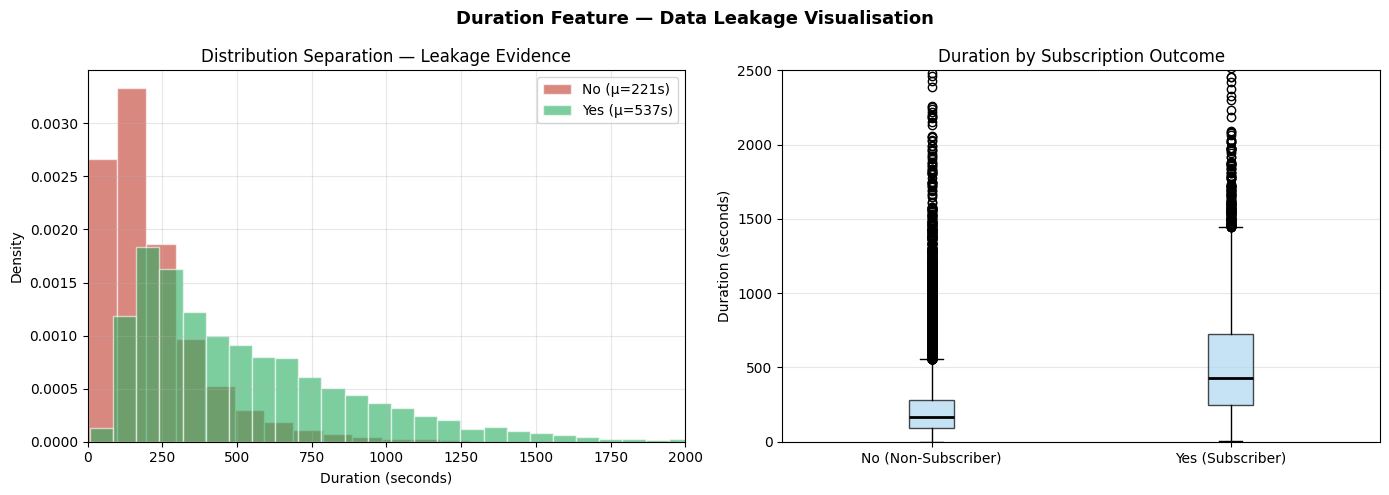

In [4]:
# 🔧 CHANGE #9: boxplot labels set via set_xticklabels (works on every matplotlib version)
# 2.0 Duration Leakage Proof — Why We Remove It
print("=" * 65)
print("DURATION LEAKAGE ANALYSIS")
print("=" * 65)

dur_yes = df[df['target']==1]['duration']
dur_no  = df[df['target']==0]['duration']

print(f"  Mean duration — Subscribers    : {dur_yes.mean():.0f} seconds ({dur_yes.mean()/60:.1f} min)")
print(f"  Mean duration — Non-Subscribers: {dur_no.mean():.0f} seconds ({dur_no.mean()/60:.1f} min)")
print(f"  Ratio                          : {dur_yes.mean()/dur_no.mean():.2f}x higher for subscribers")
print()
print("  PROBLEM: Duration is only known AFTER the call ends.")
print("  Using it = building a model to predict WHO ALREADY subscribed, not who WILL subscribe.")
print()
print("  ACTION: 'duration' and all its engineered variants are EXCLUDED from this model.")
print()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Duration Feature — Data Leakage Visualisation", fontsize=13, fontweight='bold')

axes[0].hist(dur_no,  bins=50, alpha=0.6, density=True, color='#C0392B',
             label=f'No (μ={dur_no.mean():.0f}s)', edgecolor='white')
axes[0].hist(dur_yes, bins=50, alpha=0.6, density=True, color='#27AE60',
             label=f'Yes (μ={dur_yes.mean():.0f}s)', edgecolor='white')
axes[0].set_xlabel("Duration (seconds)")
axes[0].set_ylabel("Density")
axes[0].set_title("Distribution Separation — Leakage Evidence")
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[0].set_xlim(0, 2000)

# Box plot
axes[1].boxplot([dur_no, dur_yes],
                patch_artist=True,
                boxprops=dict(facecolor='#AED6F1', alpha=0.7),
                medianprops=dict(color='black', lw=2))
axes[1].set_xticks([1, 2]); axes[1].set_xticklabels(['No (Non-Subscriber)', 'Yes (Subscriber)'])
axes[1].set_ylabel("Duration (seconds)")
axes[1].set_title("Duration by Subscription Outcome")
axes[1].grid(axis='y', alpha=0.3)
axes[1].set_ylim(0, 2500)

plt.tight_layout()
plt.savefig("00_duration_leakage_proof.png", dpi=150, bbox_inches='tight')
plt.show()

In [5]:
# 2.1 Dataset Overview — Without Duration
print("=" * 65)
print("DATASET OVERVIEW (Duration Excluded)")
print("=" * 65)

# Drop duration immediately
df_nodur = df.drop(columns=['duration'])

print(f"  Rows            : {df_nodur.shape[0]:,}")
print(f"  Columns         : {df_nodur.shape[1]}  (duration dropped)")
print(f"  Missing values  : {df_nodur.isnull().sum().sum()}")
print(f"  Duplicate rows  : {df_nodur.duplicated().sum()}")
print(f"  Event (yes)     : {df_nodur['target'].sum():,} ({df_nodur['target'].mean()*100:.1f}%)")
print(f"  Non-event (no)  : {(1-df_nodur['target']).sum():,} ({(1-df_nodur['target']).mean()*100:.1f}%)")

imbalance_ratio = (1-df_nodur['target']).sum() / df_nodur['target'].sum()
print(f"  Imbalance Ratio : {imbalance_ratio:.1f}:1  (non-event : event)")
print()

summary = pd.DataFrame({
    'dtype'   : df_nodur.dtypes,
    'n_null'  : df_nodur.isnull().sum(),
    'n_unique': df_nodur.nunique(),
    'sample'  : [df_nodur[c].dropna().sample(min(3,len(df_nodur))).tolist() for c in df_nodur.columns]
})
print(summary.to_string())

DATASET OVERVIEW (Duration Excluded)
  Rows            : 45,211
  Columns         : 17  (duration dropped)
  Missing values  : 0
  Duplicate rows  : 16
  Event (yes)     : 5,289 (11.7%)
  Non-event (no)  : 39,922 (88.3%)
  Imbalance Ratio : 7.5:1  (non-event : event)

            dtype  n_null  n_unique                                 sample
age         int64       0        77                           [19, 52, 33]
job        object       0        12  [blue-collar, technician, technician]
marital    object       0         3          [married, divorced, divorced]
education  object       0         4      [secondary, secondary, secondary]
default    object       0         2                           [no, no, no]
balance     int64       0      7168                         [5799, 38, 49]
housing    object       0         2                         [yes, yes, no]
loan       object       0         2                          [no, no, yes]
contact    object       0         3           [unknown, 

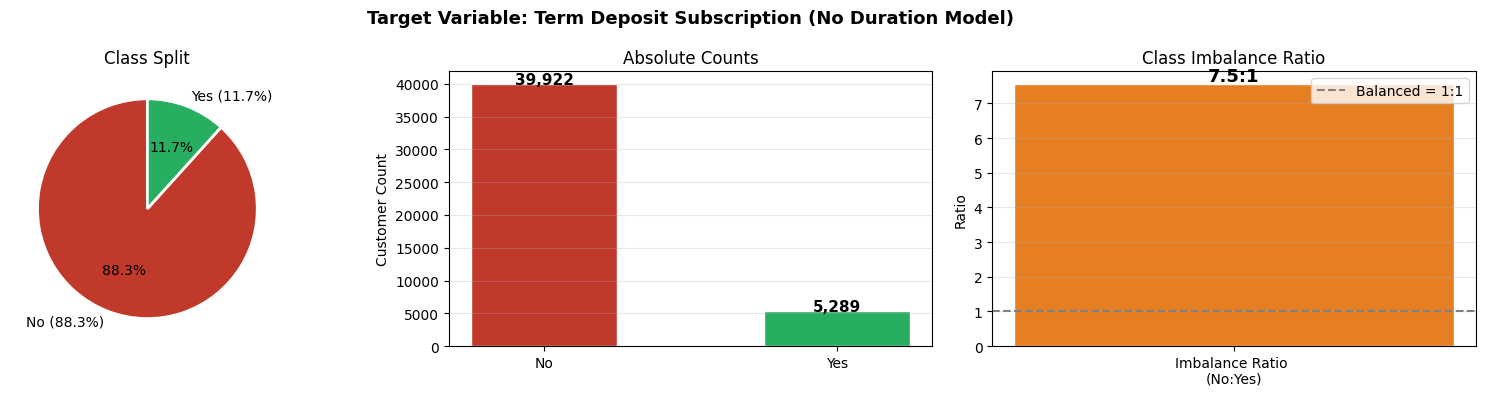

In [6]:
# 2.2 Target Distribution
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
fig.suptitle("Target Variable: Term Deposit Subscription (No Duration Model)",
             fontsize=13, fontweight='bold')

counts  = df_nodur['y'].value_counts()
no_pct  = counts['no']  / len(df_nodur) * 100
yes_pct = counts['yes'] / len(df_nodur) * 100

axes[0].pie(counts.values,
            labels=[f'No ({no_pct:.1f}%)', f'Yes ({yes_pct:.1f}%)'],
            colors=['#C0392B','#27AE60'], autopct='%1.1f%%',
            startangle=90, wedgeprops={'edgecolor':'white','linewidth':2})
axes[0].set_title("Class Split")

bars = axes[1].bar(['No','Yes'], counts.values,
                   color=['#C0392B','#27AE60'], edgecolor='white', width=0.5)
for b, v in zip(bars, counts.values):
    axes[1].text(b.get_x()+b.get_width()/2, v+100, f'{v:,}',
                 ha='center', fontweight='bold', fontsize=11)
axes[1].set_ylabel("Customer Count")
axes[1].set_title("Absolute Counts")
axes[1].grid(axis='y', alpha=0.3)

axes[2].bar(['Imbalance Ratio \n(No:Yes)'], [imbalance_ratio],
            color='#E67E22', edgecolor='white', width=0.4)
axes[2].axhline(1, color='gray', ls='--', lw=1.5, label='Balanced = 1:1')
axes[2].text(0, imbalance_ratio+0.1, f'{imbalance_ratio:.1f}:1',
             ha='center', fontweight='bold', fontsize=13)
axes[2].set_ylabel("Ratio"); axes[2].set_title("Class Imbalance Ratio")
axes[2].legend(); axes[2].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig("01_target.png", dpi=150, bbox_inches='tight')
plt.show()

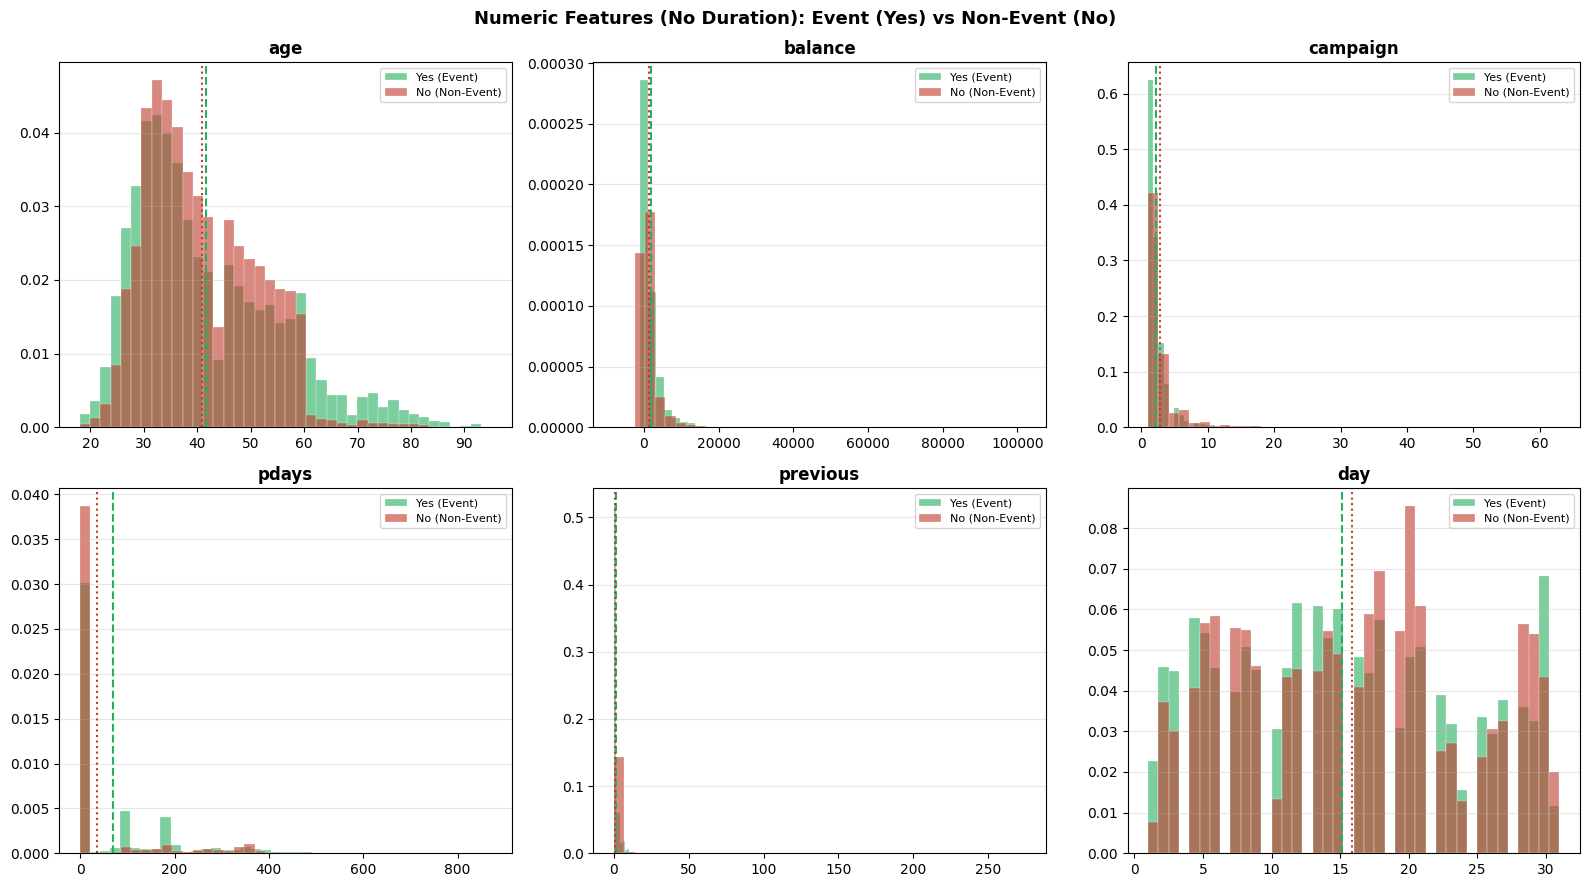

In [7]:
# 2.3 Numeric Feature Distributions (Event vs Non-Event) — No Duration
# Note: duration is excluded; we add 'day' for completeness
num_cols = ['age', 'balance', 'campaign', 'pdays', 'previous', 'day']

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
fig.suptitle("Numeric Features (No Duration): Event (Yes) vs Non-Event (No)",
             fontsize=13, fontweight='bold')
pal    = {1:'#27AE60', 0:'#C0392B'}
labels = {1:'Yes (Event)', 0:'No (Non-Event)'}

for ax, col in zip(axes.flatten(), num_cols):
    for tgt in [1, 0]:
        ax.hist(df_nodur[df_nodur['target']==tgt][col], bins=40, alpha=0.6,
                label=labels[tgt], color=pal[tgt], density=True,
                edgecolor='white', linewidth=0.3)
    ax.set_title(col, fontweight='bold')
    ax.legend(fontsize=8); ax.grid(axis='y', alpha=0.3)
    for tgt, ls in [(1,'--'),(0,':')]:
        m = df_nodur[df_nodur['target']==tgt][col].mean()
        ax.axvline(m, color=pal[tgt], ls=ls, lw=1.5)

plt.tight_layout()
plt.savefig("02_numeric_dist.png", dpi=150, bbox_inches='tight')
plt.show()

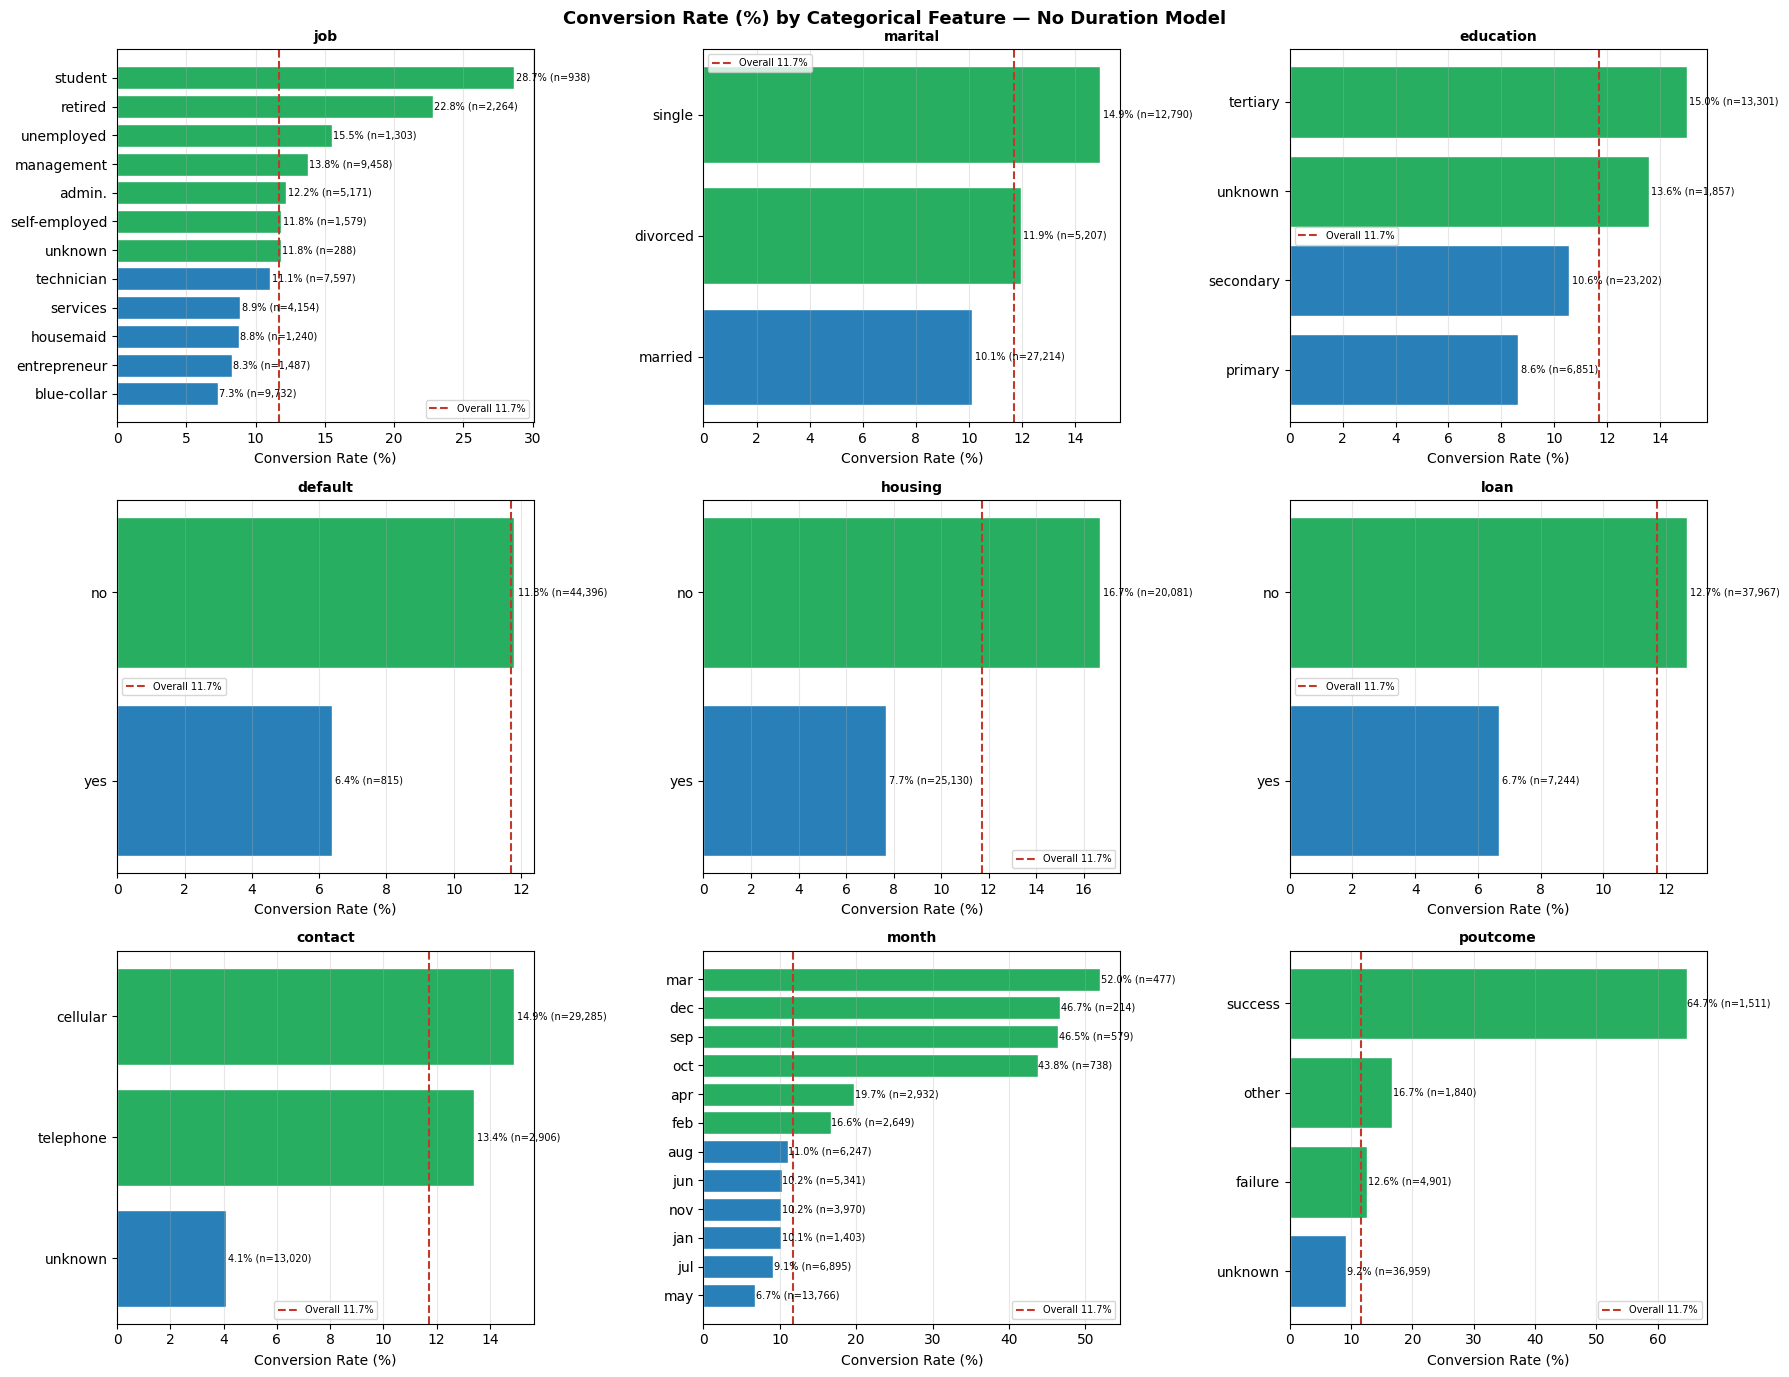

In [8]:
# 2.4 Categorical Conversion Rates
cat_cols     = ['job','marital','education','default','housing',
                'loan','contact','month','poutcome']
overall_rate = df_nodur['target'].mean() * 100

fig, axes = plt.subplots(3, 3, figsize=(18, 14))
fig.suptitle("Conversion Rate (%) by Categorical Feature — No Duration Model",
             fontsize=13, fontweight='bold')

for ax, col in zip(axes.flatten(), cat_cols):
    ct = df_nodur.groupby(col)['target'].agg(['mean','sum','count']).reset_index()
    ct['rate'] = ct['mean'] * 100
    ct = ct.sort_values('rate', ascending=True)
    colors = ['#27AE60' if r >= overall_rate else '#2980B9' for r in ct['rate']]
    bars = ax.barh(ct[col], ct['rate'], color=colors, edgecolor='white')
    ax.axvline(overall_rate, color='#C0392B', ls='--', lw=1.5,
               label=f'Overall {overall_rate:.1f}%')
    ax.set_title(col, fontweight='bold', fontsize=10)
    ax.set_xlabel("Conversion Rate (%)")
    for b, (_, row) in zip(bars, ct.iterrows()):
        ax.text(row['rate']+0.1, b.get_y()+b.get_height()/2,
                f"{row['rate']:.1f}% (n={int(row['count']):,})",
                va='center', fontsize=7)
    ax.legend(fontsize=7); ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig("03_cat_rates.png", dpi=150, bbox_inches='tight')
plt.show()

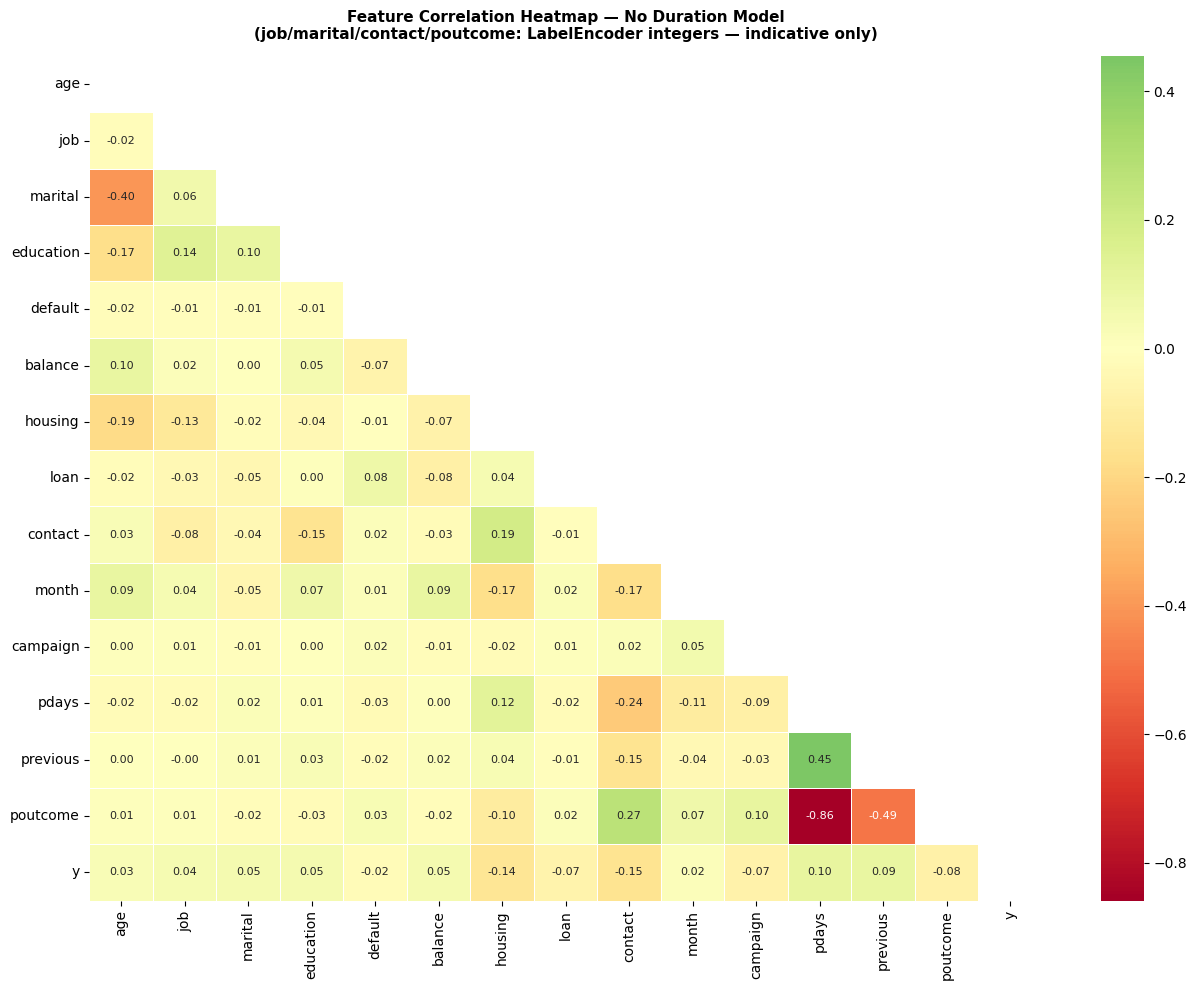

In [9]:
# 2.5 Correlation Heatmap — No Duration
df_corr = df_nodur.copy()
for c in ['default','housing','loan']:
    df_corr[c] = df_corr[c].map({'yes':1,'no':0})
df_corr['education'] = df_corr['education'].map(
    {'unknown':0,'primary':1,'secondary':2,'tertiary':3})
mmap = {'jan':1,'feb':2,'mar':3,'apr':4,'may':5,'jun':6,
        'jul':7,'aug':8,'sep':9,'oct':10,'nov':11,'dec':12}
df_corr['month'] = df_corr['month'].map(mmap)
for c in ['job','marital','contact','poutcome','y']:
    df_corr[c] = LabelEncoder().fit_transform(df_corr[c].astype(str))
df_corr = df_corr.drop(columns=['day','target'], errors='ignore')

plt.figure(figsize=(13, 10))
mask = np.triu(np.ones_like(df_corr.corr(), dtype=bool))
sns.heatmap(df_corr.corr(), annot=True, fmt='.2f', mask=mask,
            cmap='RdYlGn', center=0, linewidths=0.5, annot_kws={'size':8})
plt.title("Feature Correlation Heatmap — No Duration Model\n"
          "(job/marital/contact/poutcome: LabelEncoder integers — indicative only)",
          fontsize=11, fontweight='bold', pad=12)
plt.tight_layout()
plt.savefig("04_correlation.png", dpi=150, bbox_inches='tight')
plt.show()

## Section 3: Weight of Evidence (WoE) & Information Value (IV)

**Key Change:** `duration` is excluded from IV calculation.  
The IV table now reflects the **true predictive power** of pre-call features — no inflated leakage variable.

**IV Interpretation Guide:**
| IV Range | Predictive Power |
|---|---|
| < 0.02 | Useless |
| 0.02 – 0.10 | Weak |
| 0.10 – 0.30 | Medium |
| 0.30 – 0.50 | Strong |
| > 0.50 | Suspicious (possible data leakage) |

In [10]:
# 🔧 CHANGE #5 / #1: split FIRST. IV, balance cut-points, correlation pruning and thresholds
# must only ever see the rows they are allowed to see.  Same seeds as v1 -> same 70/15/15 rows.
tr_val_idx, te_idx = train_test_split(df_nodur.index, test_size=0.15, random_state=101,
                                      stratify=df_nodur['target'])
tr_idx, va_idx = train_test_split(tr_val_idx, test_size=0.176, random_state=101,
                                  stratify=df_nodur.loc[tr_val_idx, 'target'])
print(f"Train {len(tr_idx):,} | Val {len(va_idx):,} | Test {len(te_idx):,}")

Train 31,665 | Val 6,764 | Test 6,782


In [11]:
# 🔧 CHANGE #5: IV computed on TRAIN rows only
def compute_woe_iv(df, feature, target, bins=10, min_samples=50):
    df_woe = df[[feature, target]].copy()
    total_event    = df_woe[target].sum()
    total_nonevent = (1 - df_woe[target]).sum()

    if df_woe[feature].dtype in [np.int64, np.float64]:
        try:
            df_woe['bin'] = pd.qcut(df_woe[feature], q=bins,
                                     duplicates='drop').astype(str)
        except Exception:
            df_woe['bin'] = pd.cut(df_woe[feature], bins=bins,
                                    duplicates='drop').astype(str)
    else:
        df_woe['bin'] = df_woe[feature].astype(str)

    grouped = df_woe.groupby('bin')[target].agg(['sum','count'])
    grouped.columns = ['event','total']
    grouped['nonevent']      = grouped['total'] - grouped['event']
    grouped['event_rate']    = (grouped['event']    / total_event).clip(1e-6)
    grouped['nonevent_rate'] = (grouped['nonevent'] / total_nonevent).clip(1e-6)
    grouped['WoE']           = np.log(grouped['event_rate'] / grouped['nonevent_rate'])
    grouped['IV']            = (grouped['event_rate'] - grouped['nonevent_rate']) * grouped['WoE']
    grouped                  = grouped[grouped['total'] >= min_samples]

    iv_total       = grouped['IV'].sum()
    grouped['feature'] = feature
    return grouped.reset_index(), iv_total

# ── Features for IV — duration EXCLUDED ──────────────────────────────────────
features_for_iv = ['age','balance','campaign','pdays','previous','day',
                   'job','marital','education','default','housing','loan',
                   'contact','month','poutcome']

iv_summary, woe_tables = [], {}

for feat in features_for_iv:
    woe_df, iv = compute_woe_iv(df_nodur.loc[tr_idx], feat, 'target')
    iv_summary.append({'feature': feat, 'IV': iv})
    woe_tables[feat] = woe_df

iv_df = pd.DataFrame(iv_summary).sort_values('IV', ascending=False).reset_index(drop=True)

def classify_iv(iv):
    if iv < 0.02:   return 'Useless'
    elif iv < 0.10: return 'Weak'
    elif iv < 0.30: return 'Medium'
    elif iv < 0.50: return 'Strong'
    else:           return 'Suspicious/Check Leakage'

iv_df['Predictive_Power'] = iv_df['IV'].apply(classify_iv)
print("Information Value Summary (No Duration):")
print(iv_df.to_string(index=False))

Information Value Summary (No Duration):
  feature     IV Predictive_Power
 poutcome 0.4850           Strong
    month 0.4474           Strong
  contact 0.2882           Medium
  housing 0.1901           Medium
      job 0.1597           Medium
      age 0.1134           Medium
 previous 0.1063           Medium
  balance 0.1036           Medium
 campaign 0.0691             Weak
      day 0.0597             Weak
education 0.0590             Weak
     loan 0.0532             Weak
  marital 0.0472             Weak
    pdays 0.0109          Useless
  default 0.0060          Useless


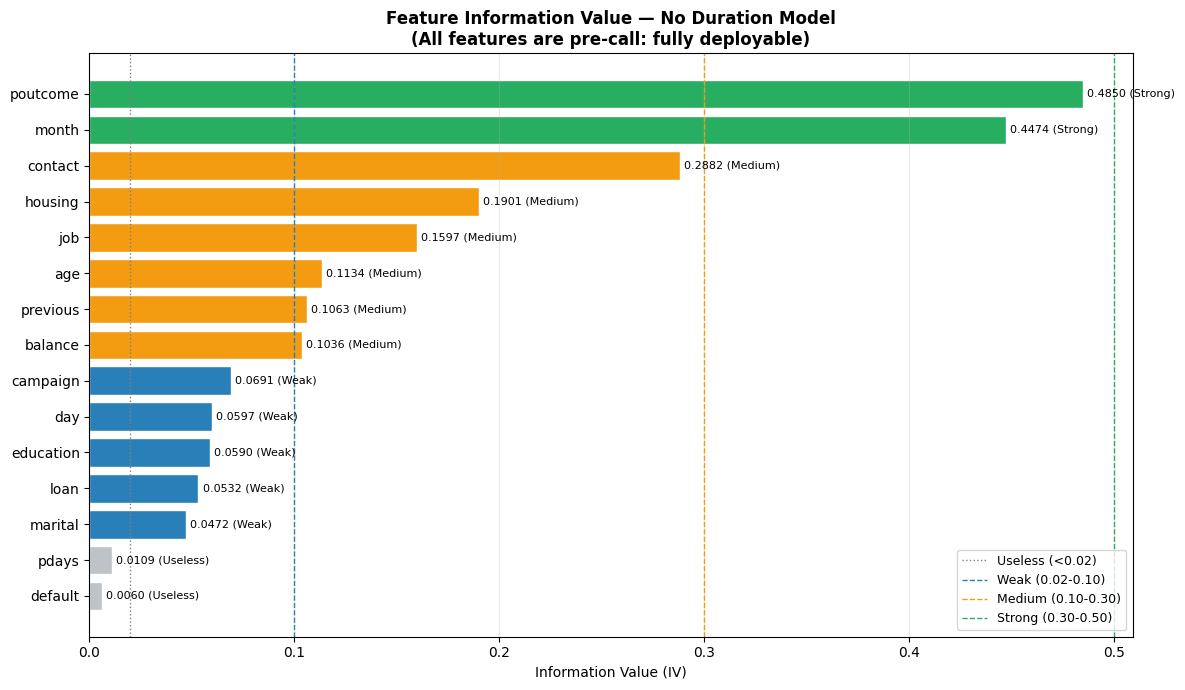

Raw features with IV < 0.02 (kept: pdays/default feed engineered features): ['pdays', 'default']


In [12]:
# IV Bar Chart — No Duration
fig, ax = plt.subplots(figsize=(12, 7))
colors = iv_df['IV'].apply(lambda x:
    '#C0392B' if x > 0.50 else
    '#27AE60' if x >= 0.30 else
    '#F39C12' if x >= 0.10 else
    '#2980B9' if x >= 0.02 else '#BDC3C7'
)
bars = ax.barh(iv_df['feature'][::-1], iv_df['IV'][::-1],
               color=colors[::-1], edgecolor='white')
ax.axvline(0.02, color='gray',    ls=':', lw=1, label='Useless (<0.02)')
ax.axvline(0.10, color='#2980B9', ls='--',lw=1, label='Weak (0.02-0.10)')
ax.axvline(0.30, color='#F39C12', ls='--',lw=1, label='Medium (0.10-0.30)')
ax.axvline(0.50, color='#27AE60', ls='--',lw=1, label='Strong (0.30-0.50)')
for b, (_, row) in zip(bars[::-1], iv_df.iterrows()):
    ax.text(row['IV']+0.002, b.get_y()+b.get_height()/2,
            f"{row['IV']:.4f} ({row['Predictive_Power']})",
            va='center', fontsize=8)
ax.set_xlabel("Information Value (IV)")
ax.set_title("Feature Information Value — No Duration Model\n"
             "(All features are pre-call: fully deployable)",
             fontsize=12, fontweight='bold')
ax.legend(loc='lower right', fontsize=9)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig("06_iv_chart_nodur.png", dpi=150, bbox_inches='tight')
plt.show()

# 🔧 CHANGE #5: IV is used here for INSIGHT, not hard selection (v1 computed a selected list and never used it).
# Feature pruning is done in Section 5 with a train-only correlation filter instead.
weak = iv_df[iv_df['IV'] < 0.02]['feature'].tolist()
print(f"Raw features with IV < 0.02 (kept: pdays/default feed engineered features): {weak}")

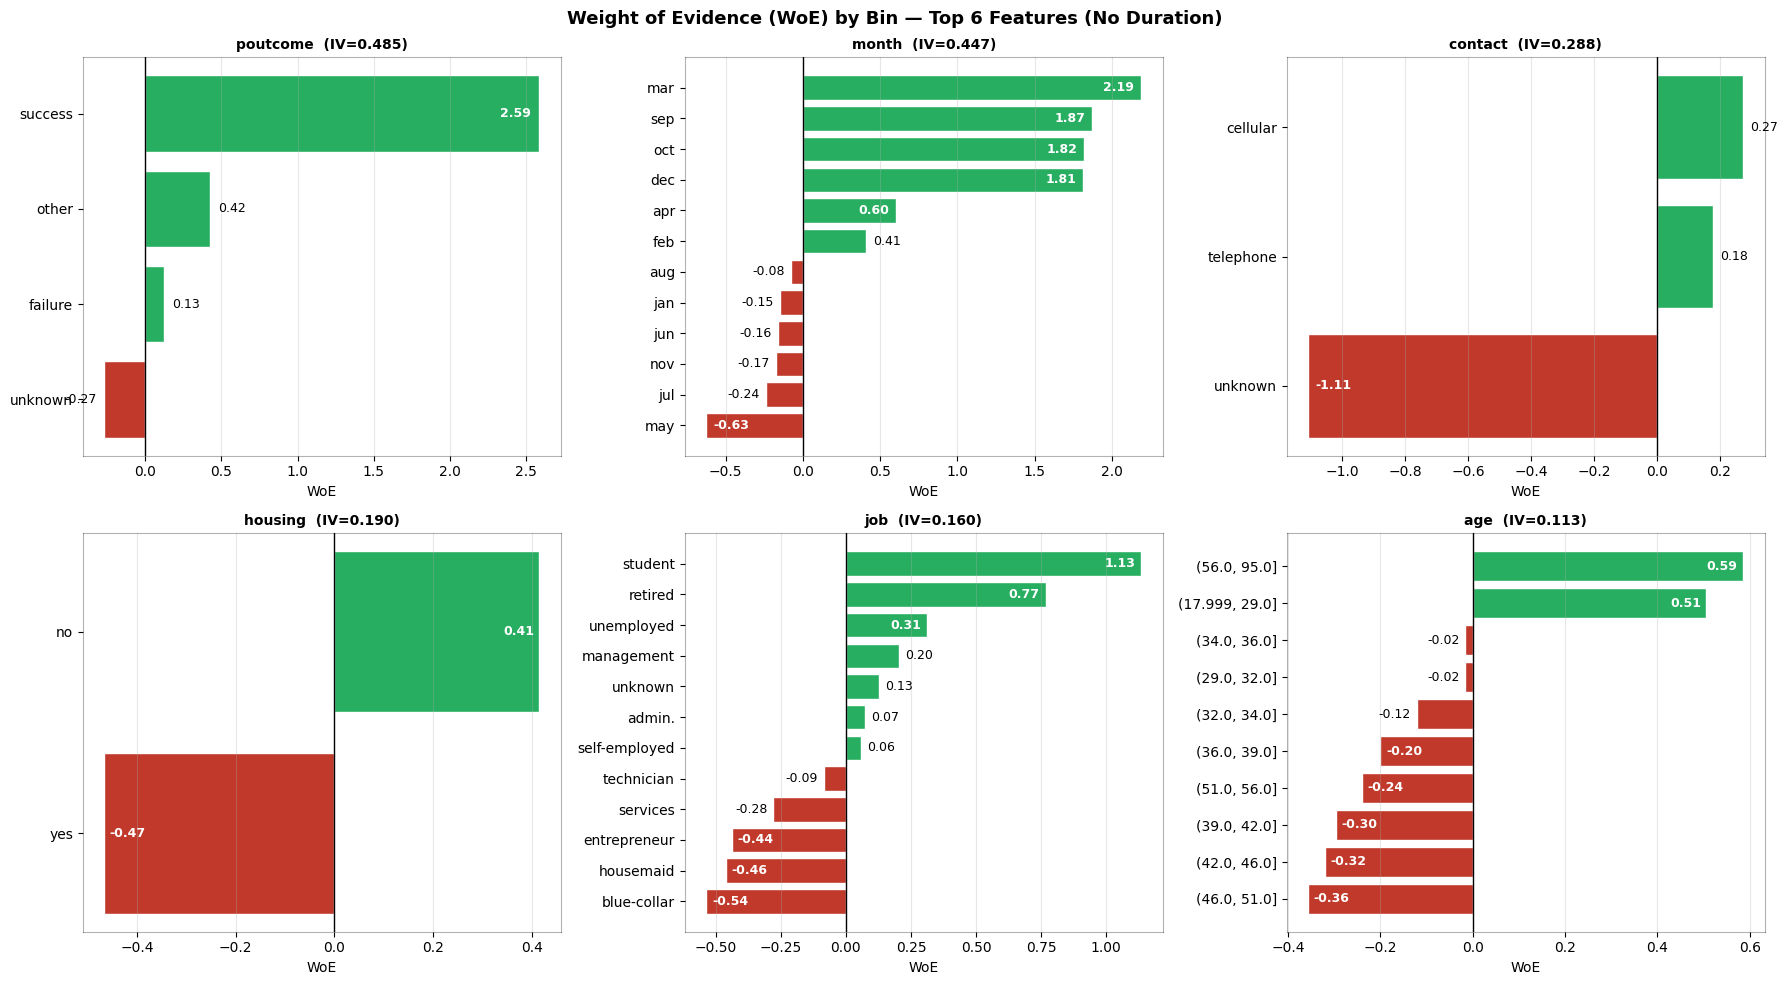

In [13]:
# 🔧 CHANGE #9: duplicate WoE cell + empty '# EXTRA' cells from v1 removed; labelled version kept below
# WoE Plot for Top-6 Features by IV (No Duration)
top_feats = iv_df.head(6)['feature'].tolist()
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle("Weight of Evidence (WoE) by Bin — Top 6 Features (No Duration)",
             fontsize=13, fontweight='bold')

for ax, feat in zip(axes.flatten(), top_feats):
    woe = woe_tables[feat].copy().sort_values('WoE')
    bar_colors = ['#27AE60' if w >= 0 else '#C0392B' for w in woe['WoE']]

    # Create the horizontal bar plot
    bars = ax.barh(woe['bin'].astype(str), woe['WoE'],
                  color=bar_colors, edgecolor='white')

    ax.axvline(0, color='black', lw=1)
    ax.set_title(f"{feat}  (IV={iv_df[iv_df['feature']==feat]['IV'].values[0]:.3f})",
                 fontweight='bold', fontsize=10)
    ax.set_xlabel("WoE")
    ax.grid(axis='x', alpha=0.3)

    # --- Add Value Labels ---
    # Determine a threshold for placing text inside vs outside the bar
    max_width = max(abs(woe['WoE'].min()), abs(woe['WoE'].max()))
    threshold = max_width * 0.25

    for bar in bars:
        width = bar.get_width()
        y_pos = bar.get_y() + bar.get_height() / 2

        # Format the label string
        label_text = f"{width:.2f}"

        if width >= 0:
            # Positive WoE
            if width > threshold:
                # Inside the bar (aligned right, white text)
                ax.text(width - (max_width * 0.02), y_pos, label_text,
                        va='center', ha='right', color='white', fontweight='bold', fontsize=9)
            else:
                # Outside the bar (aligned left, black text)
                ax.text(width + (max_width * 0.02), y_pos, label_text,
                        va='center', ha='left', color='black', fontsize=9)
        else:
            # Negative WoE
            if abs(width) > threshold:
                # Inside the bar (aligned left, white text)
                ax.text(width + (max_width * 0.02), y_pos, label_text,
                        va='center', ha='left', color='white', fontweight='bold', fontsize=9)
            else:
                # Outside the bar (aligned right, black text)
                ax.text(width - (max_width * 0.02), y_pos, label_text,
                        va='center', ha='right', color='black', fontsize=9)
    # ------------------------

    for spine in ax.spines.values():
        spine.set_alpha(0.3)

plt.tight_layout()
plt.savefig("07_woe_plots_nodur.png", dpi=150, bbox_inches='tight')
plt.show()

> 🔧 **CHANGE #4 — two things an interviewer will ask about**
>
> **`poutcome` IV = 0.51 ("Suspicious" in the table).** `poutcome` is the outcome of the *previous* campaign. It is known
> before the current call, so it is **not** leakage. Its IV is high because "success" customers convert at ~65% vs 11.7% overall (check your Section 2.4 chart),
> but 'unknown' is ~82% of rows, so the power comes from a small group of previously-converted customers. Treat it as a
> legitimate but concentrated signal.
>
> **`campaign` caveat.** In the UCI file `campaign` counts contacts *including the last one*, so it is only approximately
> pre-call. Its IV is weak (0.07), so the effect is small, but it should be re-defined as "contacts before this call" in production.

## Section 4: Feature Engineering — No Duration + Enhanced Business Features

**Key Changes from Duration Model:**
1. All `duration`-derived features (`duration_min`, `duration_bucket`) are **removed**
2. New **recency-engagement score** replaces duration as the "contact quality" signal
3. New **socio-economic profile** feature captures customer financial readiness
4. Improved **cyclical encodings** for month and seasonality
5. **Interaction features** focused on pre-call observable signals

In [14]:
%%writefile features.py
"""features.py -- feature engineering shared by the notebook AND the Streamlit app.

The notebook writes this file (%%writefile), so training and serving use identical code.
All categorical levels are fixed here, so scoring a SINGLE customer gives the same
columns as training (plain get_dummies on one row would silently drop the dummy).
"""
import numpy as np
import pandas as pd

RAW_COLS = ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan',
            'contact', 'day', 'month', 'campaign', 'pdays', 'previous', 'poutcome']

JOBS      = ['admin.', 'blue-collar', 'entrepreneur', 'housemaid', 'management', 'retired',
             'self-employed', 'services', 'student', 'technician', 'unemployed', 'unknown']
MARITAL   = ['divorced', 'married', 'single']
EDUCATION = ['unknown', 'primary', 'secondary', 'tertiary']
CONTACT   = ['cellular', 'telephone', 'unknown']
POUTCOME  = ['failure', 'other', 'success', 'unknown']
MONTHS    = ['jan', 'feb', 'mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']

AGE_LABELS = ['<25', '25-35', '35-45', '45-55', '55-65', '65+']
BAL_LABELS = ['Q1', 'Q2', 'Q3', 'Q4', 'Q5']
QUARTERS   = ['Q1', 'Q2', 'Q3', 'Q4']

MONTH_MAP = {m: i + 1 for i, m in enumerate(MONTHS)}
EDU_MAP   = {k: i for i, k in enumerate(EDUCATION)}

_CATS = {'job': JOBS, 'marital': MARITAL, 'contact': CONTACT, 'poutcome': POUTCOME,
         'age_group': AGE_LABELS, 'balance_bucket': BAL_LABELS, 'quarter': QUARTERS}


def feature_engineering_nodur(df, bal_cuts):
    """df: raw bank-marketing columns (no duration). bal_cuts: 4 balance quantile cut-points
    (20/40/60/80th percentile) learned on the TRAIN rows only."""
    d = df.copy()
    edges = [-np.inf] + [float(c) for c in bal_cuts] + [np.inf]

    # Age / balance
    d['age_group'] = pd.cut(d['age'], bins=[0, 25, 35, 45, 55, 65, 100], labels=AGE_LABELS)
    d['balance_log'] = np.log1p(np.clip(d['balance'], 0, None))
    d['has_negative_bal'] = (d['balance'] < 0).astype(int)
    d['balance_bucket'] = pd.cut(d['balance'], bins=edges, labels=BAL_LABELS, include_lowest=True)

    # Campaign fatigue (pre-call observable)
    d['campaign_log'] = np.log1p(d['campaign'])
    d['is_first_contact'] = (d['campaign'] == 1).astype(int)
    d['many_contacts'] = (d['campaign'] > 5).astype(int)

    # Prior-contact recency & engagement
    d['was_contacted_prev'] = (d['pdays'] != -1).astype(int)
    d['days_since_contact'] = d['pdays'].replace(-1, 999)
    d['days_since_contact_log'] = np.log1p(d['days_since_contact'])
    d['has_previous'] = (d['previous'] > 0).astype(int)
    d['previous_log'] = np.log1p(d['previous'])
    d['recency_score'] = np.where(d['pdays'] == -1, 0,
                         np.where(d['pdays'] <= 30, 3,
                         np.where(d['pdays'] <= 90, 2,
                         np.where(d['pdays'] <= 180, 1, 0))))
    d['engagement_index'] = d['previous'] * (d['recency_score'] + 1)

    # Seasonality
    d['month_num'] = d['month'].map(MONTH_MAP)
    d['month_sin'] = np.sin(2 * np.pi * d['month_num'] / 12)
    d['month_cos'] = np.cos(2 * np.pi * d['month_num'] / 12)
    d['is_end_of_year'] = d['month'].isin(['oct', 'nov', 'dec']).astype(int)
    d['quarter'] = d['month_num'].apply(
        lambda m: 'Q1' if m <= 3 else 'Q2' if m <= 6 else 'Q3' if m <= 9 else 'Q4')
    d['is_end_of_month'] = (d['day'] >= 25).astype(int)
    d['is_start_of_month'] = (d['day'] <= 5).astype(int)

    # Financial profile
    d['financial_stress'] = ((d['default'] == 'yes').astype(int) +
                             (d['loan'] == 'yes').astype(int) +
                             (d['housing'] == 'yes').astype(int))
    d['edu_score'] = d['education'].map(EDU_MAP).fillna(0)
    d['wealth_readiness'] = d['balance_log'] * d['edu_score'] / (d['financial_stress'] + 1)

    # Interactions / flags
    d['age_x_balance'] = d['age'] * d['balance_log']
    d['retired_flag'] = (d['job'] == 'retired').astype(int)
    d['student_flag'] = (d['job'] == 'student').astype(int)
    d['management_flag'] = (d['job'] == 'management').astype(int)
    d['prev_success_flag'] = (d['poutcome'] == 'success').astype(int)
    d['prev_failure_flag'] = (d['poutcome'] == 'failure').astype(int)
    d['age_stress'] = d['age'] * d['financial_stress']
    d['cellular_prev_success'] = (d['contact'] == 'cellular').astype(int) * d['prev_success_flag']
    return d


def encode_features_nodur(df_fe):
    d = df_fe.copy()
    for col in ['default', 'housing', 'loan']:
        d[col] = d[col].map({'yes': 1, 'no': 0})
    d['education'] = d['education'].map(EDU_MAP)

    # fixed category lists -> identical dummy columns for 1 row or 45,000 rows
    for col, cats in _CATS.items():
        d[col] = pd.Categorical(d[col].astype(str), categories=cats)
    d = pd.get_dummies(d, columns=list(_CATS), drop_first=True)

    d = d.drop(columns=[c for c in ['y', 'day', 'month', 'month_num'] if c in d.columns])
    bool_cols = d.select_dtypes('bool').columns
    d[bool_cols] = d[bool_cols].astype(int)
    return d


def build_model_matrix(raw, bal_cuts, feature_cols):
    """Raw customer rows -> model matrix with exactly the training columns (used by the app)."""
    fe = feature_engineering_nodur(raw[RAW_COLS], bal_cuts)
    enc = encode_features_nodur(fe)
    return enc.reindex(columns=feature_cols, fill_value=0).astype(float)

Writing features.py


In [15]:
# 🔧 CHANGE #10: feature engineering now lives in features.py (also used by the Streamlit app)
import importlib, features
importlib.reload(features)
from features import feature_engineering_nodur, encode_features_nodur, build_model_matrix

# 🔧 CHANGE #5: balance quintile cut-points learned on TRAIN rows only
BAL_CUTS = [float(x) for x in np.quantile(df_nodur.loc[tr_idx, 'balance'], [0.2, 0.4, 0.6, 0.8])]
print("Balance cut-points (train):", [round(c, 1) for c in BAL_CUTS])

df_fe  = feature_engineering_nodur(df_nodur, BAL_CUTS)
new_f  = [c for c in df_fe.columns if c not in df_nodur.columns]
print(f"New features ({len(new_f)}): {new_f}")

df_model = encode_features_nodur(df_fe).dropna()
print(f"Model DataFrame (No Duration): {df_model.shape}")
print(f"Features: {df_model.shape[1]-1} | Target: target")
df_model.head(2)

Balance cut-points (train): [22.0, 275.0, 703.0, 1869.0]
New features (32): ['age_group', 'balance_log', 'has_negative_bal', 'balance_bucket', 'campaign_log', 'is_first_contact', 'many_contacts', 'was_contacted_prev', 'days_since_contact', 'days_since_contact_log', 'has_previous', 'previous_log', 'recency_score', 'engagement_index', 'month_num', 'month_sin', 'month_cos', 'is_end_of_year', 'quarter', 'is_end_of_month', 'is_start_of_month', 'financial_stress', 'edu_score', 'wealth_readiness', 'age_x_balance', 'retired_flag', 'student_flag', 'management_flag', 'prev_success_flag', 'prev_failure_flag', 'age_stress', 'cellular_prev_success']
Model DataFrame (No Duration): (45211, 68)
Features: 67 | Target: target


,age,education,default,balance,housing,loan,campaign,pdays,previous,target,balance_log,has_negative_bal,campaign_log,is_first_contact,many_contacts,was_contacted_prev,days_since_contact,days_since_contact_log,has_previous,previous_log,recency_score,engagement_index,month_sin,month_cos,is_end_of_year,is_end_of_month,is_start_of_month,financial_stress,edu_score,wealth_readiness,age_x_balance,retired_flag,student_flag,management_flag,prev_success_flag,prev_failure_flag,age_stress,cellular_prev_success,job_blue-collar,job_entrepreneur,job_housemaid,job_management,job_retired,job_self-employed,job_services,job_student,job_technician,job_unemployed,job_unknown,marital_married,marital_single,contact_telephone,contact_unknown,poutcome_other,poutcome_success,poutcome_unknown,age_group_25-35,age_group_35-45,age_group_45-55,age_group_55-65,age_group_65+,balance_bucket_Q2,balance_bucket_Q3,balance_bucket_Q4,balance_bucket_Q5,quarter_Q2,quarter_Q3,quarter_Q4
0,58,3,0,2143,1,0,1,-1,0,0,7.6704,0,0.6931,1,0,0,999,6.9078,0,0.0000,0,0,0.5000,-0.8660,0,0,1,1,3,11.5056,444.8849,0,0,1,0,0,58,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,1,0,0,1,0,0,0,1,0,0,0,0,1,1,0,0
1,44,2,0,29,1,0,1,-1,0,0,3.4012,0,0.6931,1,0,0,999,6.9078,0,0.0000,0,0,0.5000,-0.8660,0,0,1,1,2,3.4012,149.6527,0,0,0,0,0,44,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,1,0,0,1,0,1,0,0,0,1,0,0,0,1,0,0


## Section 5: Train / Validation / Test Split + SMOTE

**Why SMOTE on training set only?**
- Test and validation sets must reflect real-world distribution (imbalanced) for honest evaluation
- SMOTE is fitted and applied **only** on the training set — never on val/test
- This prevents data leakage and ensures metrics reflect actual deployment performance

**Note on PSI (see Section 10 for the v2 approach):** In this model, PSI is computed correctly — train scores vs test scores both from the **original imbalanced** distributions. This avoids the inflated PSI we saw in the duration model (PSI=4.17 was partly due to SMOTE-expanded train set score distribution mismatch).

In [16]:
df_model.sample(2)

,age,education,default,balance,housing,loan,campaign,pdays,previous,target,balance_log,has_negative_bal,campaign_log,is_first_contact,many_contacts,was_contacted_prev,days_since_contact,days_since_contact_log,has_previous,previous_log,recency_score,engagement_index,month_sin,month_cos,is_end_of_year,is_end_of_month,is_start_of_month,financial_stress,edu_score,wealth_readiness,age_x_balance,retired_flag,student_flag,management_flag,prev_success_flag,prev_failure_flag,age_stress,cellular_prev_success,job_blue-collar,job_entrepreneur,job_housemaid,job_management,job_retired,job_self-employed,job_services,job_student,job_technician,job_unemployed,job_unknown,marital_married,marital_single,contact_telephone,contact_unknown,poutcome_other,poutcome_success,poutcome_unknown,age_group_25-35,age_group_35-45,age_group_45-55,age_group_55-65,age_group_65+,balance_bucket_Q2,balance_bucket_Q3,balance_bucket_Q4,balance_bucket_Q5,quarter_Q2,quarter_Q3,quarter_Q4
8471,32,2,0,471,1,0,2,-1,0,0,6.1570,0,1.0986,0,0,0,999,6.9078,0,0.0000,0,0,0.0000,-1.0000,0,0,1,1,2,6.1570,197.0233,0,0,0,0,0,32,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,1,0,0,1,1,0,0,0,0,0,1,0,0,1,0,0
18821,50,2,0,297,1,0,10,-1,0,0,5.6971,0,2.3979,0,1,0,999,6.9078,0,0.0000,0,0,-0.5000,-0.8660,0,1,0,1,2,5.6971,284.8547,0,0,0,0,0,50,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,1,0,0,1,0,0,0,1,0,0,0,1,0


In [17]:
# 🔧 CHANGE #5 / #1: use the index split from Section 3 + train-only correlation pruning
TARGET       = 'target'
ALL_FEATURES = [c for c in df_model.columns if c != TARGET]

X_train, y_train = df_model.loc[tr_idx, ALL_FEATURES], df_model.loc[tr_idx, TARGET]
X_val,   y_val   = df_model.loc[va_idx, ALL_FEATURES], df_model.loc[va_idx, TARGET]
X_test,  y_test  = df_model.loc[te_idx, ALL_FEATURES], df_model.loc[te_idx, TARGET]

# drop one of every pair of features with |corr| > 0.90 (computed on TRAIN only)
corr   = X_train.corr().abs()
upper  = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
to_drop = [c for c in upper.columns if (upper[c] > 0.90).any()]
FEATURES = [c for c in ALL_FEATURES if c not in to_drop]
X_train, X_val, X_test = X_train[FEATURES], X_val[FEATURES], X_test[FEATURES]

print(f"Dropped {len(to_drop)} highly-correlated features: {to_drop}")
print(f"Features kept: {len(FEATURES)} (of {len(ALL_FEATURES)})")
print()
print("Before SMOTE:")
print(f"  Train : {X_train.shape[0]:,}  |  event rate: {y_train.mean()*100:.1f}%")
print(f"  Val   : {X_val.shape[0]:,}   |  event rate: {y_val.mean()*100:.1f}%")
print(f"  Test  : {X_test.shape[0]:,}  |  event rate: {y_test.mean()*100:.1f}%")

Dropped 12 highly-correlated features: ['days_since_contact', 'days_since_contact_log', 'has_previous', 'edu_score', 'age_stress', 'cellular_prev_success', 'job_management', 'job_retired', 'job_student', 'poutcome_success', 'poutcome_unknown', 'quarter_Q4']
Features kept: 55 (of 67)

Before SMOTE:
  Train : 31,665  |  event rate: 11.7%
  Val   : 6,764   |  event rate: 11.7%
  Test  : 6,782  |  event rate: 11.7%


In [18]:
from imblearn.over_sampling import SMOTE

# ── SMOTE: Apply ONLY on training set ─────────────────────────────────────
smote = SMOTE(random_state=42, k_neighbors=5)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

print("After SMOTE (training set only):")
print(f"  Train : {X_train_res.shape[0]:,}  |  event rate: {y_train_res.mean()*100:.1f}%")
print(f"  Val   : {X_val.shape[0]:,}          |  event rate: {y_val.mean()*100:.1f}%  (unchanged)")
print(f"  Test  : {X_test.shape[0]:,}         |  event rate: {y_test.mean()*100:.1f}%  (unchanged)")
print()
print(f"  SMOTE added : {X_train_res.shape[0] - X_train.shape[0]:,} synthetic minority samples")

imbalance_ratio_train = (y_train == 0).sum() / (y_train == 1).sum()
print(f"  Original train imbalance ratio: {imbalance_ratio_train:.2f}")

# Scale for Logistic Regression only
scaler     = StandardScaler()
X_train_sc = scaler.fit_transform(X_train_res)
X_val_sc   = scaler.transform(X_val)
X_test_sc  = scaler.transform(X_test)

After SMOTE (training set only):
  Train : 55,920  |  event rate: 50.0%
  Val   : 6,764          |  event rate: 11.7%  (unchanged)
  Test  : 6,782         |  event rate: 11.7%  (unchanged)

  SMOTE added : 24,255 synthetic minority samples
  Original train imbalance ratio: 7.55


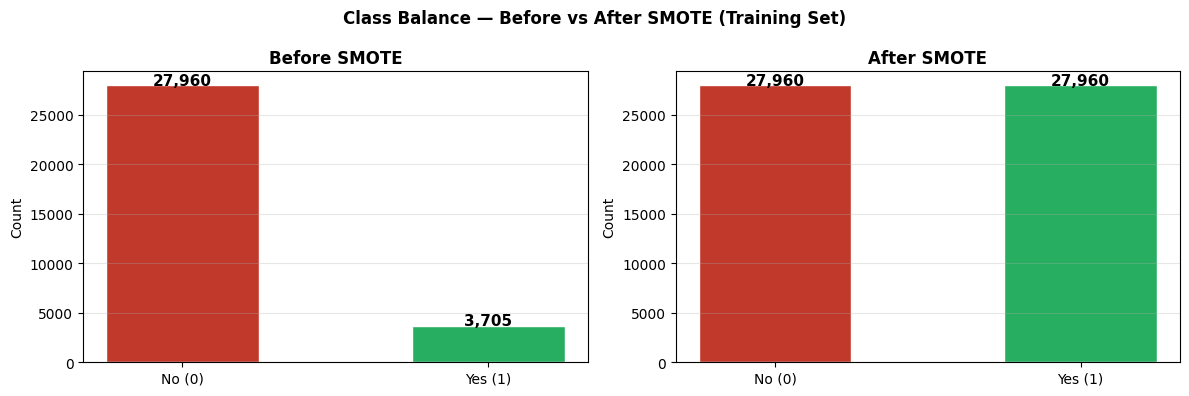

In [19]:
# Visualise class balance before/after SMOTE
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle("Class Balance — Before vs After SMOTE (Training Set)", fontsize=12, fontweight='bold')

for ax, counts, title in zip(
    axes,
    [y_train.value_counts(), y_train_res.value_counts()],
    ["Before SMOTE", "After SMOTE"]
):
    bars = ax.bar(['No (0)','Yes (1)'], [counts.get(0,0), counts.get(1,0)],
                  color=['#C0392B','#27AE60'], edgecolor='white', width=0.5)
    for b, v in zip(bars, [counts.get(0,0), counts.get(1,0)]):
        ax.text(b.get_x()+b.get_width()/2, v+50, f'{v:,}',
                ha='center', fontweight='bold', fontsize=11)
    ax.set_title(title, fontweight='bold')
    ax.set_ylabel("Count"); ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig("05b_smote_balance.png", dpi=150, bbox_inches='tight')
plt.show()

## Section 6: Model Training, Leak-free CV, Imbalance Strategy & Calibration

> 🔧 **CHANGE #2, #6, #7** live in this section.

**Expected performance drop vs the Duration model is normal:** without the leaky `duration` feature AUC is ~0.78, not 0.91.
That is the **true, deployable** performance.

Order of work: (1) benchmark 4 algorithms -> (2) leak-free CV -> (3) is SMOTE even needed? -> (4) calibrate probabilities.

In [20]:
models = {
    "Logistic Regression": LogisticRegression(
        C=0.5, max_iter=1000, random_state=101, class_weight='balanced'),

    "Random Forest": RandomForestClassifier(
        n_estimators=300, max_depth=8, min_samples_leaf=5,
        class_weight='balanced', random_state=101, n_jobs=-1),

    "XGBoost": xgb.XGBClassifier(
        n_estimators=400, max_depth=5, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8, min_child_weight=5,
        scale_pos_weight=1,
        eval_metric='logloss',
        random_state=101, n_jobs=-1, verbosity=0),

    "LightGBM": lgb.LGBMClassifier(
        n_estimators=400, max_depth=5, learning_rate=0.05,
        num_leaves=50, subsample=0.8, colsample_bytree=0.8,
        min_child_samples=20, is_unbalance=False,
        random_state=101, n_jobs=-1, verbose=-1),
}

results, trained_models = {}, {}
print(f"{'Model':<25} {'Val AUC':>8} {'Val KS':>8} {'Val Gini':>9} {'Val F1':>8}")
print("=" * 65)

for name, model in models.items():
    Xtr = X_train_sc if "Logistic" in name else X_train_res
    Xvl = X_val_sc   if "Logistic" in name else X_val
    ytr = y_train_res

    model.fit(Xtr, ytr)
    proba = model.predict_proba(Xvl)[:, 1]
    pred  = (proba >= 0.5).astype(int)

    auc  = roc_auc_score(y_val, proba)
    gini = 2 * auc - 1
    fpr, tpr, _ = roc_curve(y_val, proba)
    ks   = float(np.max(tpr - fpr))
    f1   = f1_score(y_val, pred)

    results[name]        = {'auc':auc,'gini':gini,'ks':ks,'f1':f1,
                            'proba':proba,'pred':pred}
    trained_models[name] = model
    print(f"{name:<25} {auc:>8.4f} {ks:>8.4f} {gini:>9.4f} {f1:>8.4f}")

best_name = max(results, key=lambda k: results[k]['auc'])
print(f"\nBest Model (Val AUC): {best_name}  ==>  AUC={results[best_name]['auc']:.4f}")
print()
print("NOTE: AUC lower than duration model is EXPECTED and CORRECT.")
print("      This is the honest, deployable performance without data leakage.")

Model                      Val AUC   Val KS  Val Gini   Val F1
Logistic Regression         0.7149   0.3154    0.4299   0.3264
Random Forest               0.7786   0.4487    0.5572   0.4345
XGBoost                     0.7908   0.4591    0.5817   0.3855
LightGBM                    0.7861   0.4566    0.5722   0.3871

Best Model (Val AUC): XGBoost  ==>  AUC=0.7908

NOTE: AUC lower than duration model is EXPECTED and CORRECT.
      This is the honest, deployable performance without data leakage.


In [21]:
# 🔧 CHANGE #2: SMOTE must run INSIDE each CV fold. v1 cross-validated on already-SMOTE'd data, so synthetic
# neighbours of a validation row sat in the training folds -> AUC 0.97 (fake). This is the honest number.
from imblearn.pipeline import Pipeline as ImbPipeline

proto = trained_models[best_name]
steps = [('smote', SMOTE(random_state=42, k_neighbors=5))]
if 'Logistic' in best_name:
    steps.append(('scaler', StandardScaler()))
steps.append(('clf', clone(proto)))
cv_pipe = ImbPipeline(steps)

cv  = StratifiedKFold(n_splits=5, shuffle=True, random_state=101)
res = cross_validate(cv_pipe, X_train, y_train, cv=cv, n_jobs=1,
                     scoring={'auc': 'roc_auc', 'ap': 'average_precision'})
print(f"5-Fold CV — {best_name} (SMOTE inside each fold, ORIGINAL train rows)")
print(f"  AUC : {res['test_auc'].mean():.4f} +/- {res['test_auc'].std():.4f}")
print(f"  PR-AUC (avg precision) : {res['test_ap'].mean():.4f} +/- {res['test_ap'].std():.4f}")
print()
print("Compare with the validation AUC above: they should now agree (~0.78). v1's 0.97 was leakage.")

5-Fold CV — XGBoost (SMOTE inside each fold, ORIGINAL train rows)
  AUC : 0.7806 +/- 0.0082
  PR-AUC (avg precision) : 0.4097 +/- 0.0174

Compare with the validation AUC above: they should now agree (~0.78). v1's 0.97 was leakage.


In [22]:
# 🔧 CHANGE #7: Do we even need SMOTE?  Same XGBoost, three imbalance strategies, judged on VALIDATION.
xgb_params = dict(n_estimators=400, max_depth=5, learning_rate=0.05, subsample=0.8,
                  colsample_bytree=0.8, min_child_weight=5, eval_metric='logloss',
                  random_state=101, n_jobs=-1, verbosity=0)
POS_WEIGHT = float((y_train == 0).sum() / (y_train == 1).sum())

def fit_xgb(X, y, strategy):
    """strategy: 'smote' | 'class_weight' | 'plain'  (same recipe is reused in Section 10 and by the app)"""
    if strategy == 'smote':
        Xr, yr = SMOTE(random_state=42, k_neighbors=5).fit_resample(X, y)
        return xgb.XGBClassifier(**xgb_params, scale_pos_weight=1).fit(Xr, yr)
    if strategy == 'class_weight':
        w = float((y == 0).sum() / (y == 1).sum())
        return xgb.XGBClassifier(**xgb_params, scale_pos_weight=w).fit(X, y)
    return xgb.XGBClassifier(**xgb_params, scale_pos_weight=1).fit(X, y)

strategy_names = {'smote': 'XGBoost + SMOTE', 'class_weight': 'XGBoost + class weight',
                  'plain': 'XGBoost plain'}
strategy_models, rows = {}, []
for key, label in strategy_names.items():
    m = fit_xgb(X_train, y_train, key)
    p = m.predict_proba(X_val)[:, 1]
    strategy_models[key] = m
    rows.append({'Strategy': label, 'Val AUC': roc_auc_score(y_val, p),
                 'Val PR-AUC': average_precision_score(y_val, p)})
strat_df = pd.DataFrame(rows).set_index('Strategy')
print(strat_df.round(4).to_string())

FINAL_STRATEGY = max(strategy_names, key=lambda k: strat_df.loc[strategy_names[k], 'Val AUC'])
final_model    = strategy_models[FINAL_STRATEGY]
final_name     = strategy_names[FINAL_STRATEGY]
best_name      = final_name          # used in plot titles below
print(f"\nSelected on validation AUC: {final_name}")
print("If SMOTE is not clearly better, say so in your write-up — that finding is itself a good talking point.")

                        Val AUC  Val PR-AUC
Strategy                                   
XGBoost + SMOTE          0.7908      0.4485
XGBoost + class weight   0.7976      0.4647
XGBoost plain            0.8001      0.4633

Selected on validation AUC: XGBoost plain
If SMOTE is not clearly better, say so in your write-up — that finding is itself a good talking point.


Platt: p = sigmoid(0.977 * logit(raw) + -0.050)
Brier score on TEST  raw: 0.0841  ->  calibrated: 0.0840
Mean predicted prob (test) raw 0.119 | calibrated 0.118 | actual event rate 0.117
AUC unchanged: raw 0.7880 | calibrated 0.7880


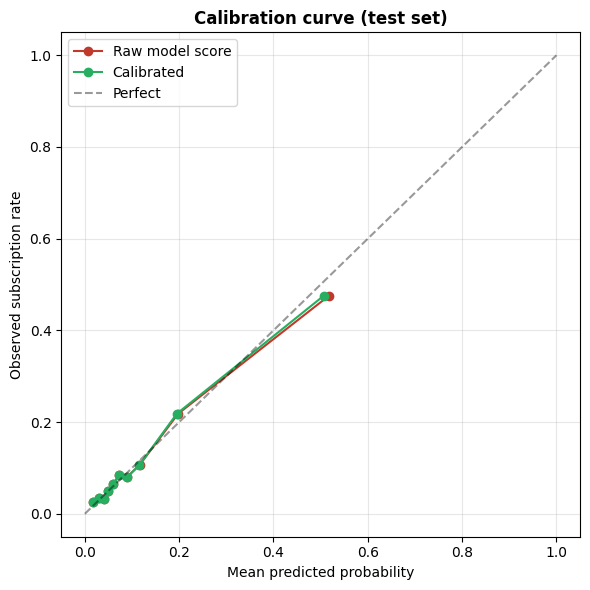

In [23]:
# 🔧 CHANGE #6: calibrate. SMOTE / class weights shift the raw scores away from real probabilities, so a
# threshold like 0.11 or a cost model is meaningless on raw scores.  Platt scaling is fitted on VALIDATION,
# is monotonic (ranking, AUC and deciles are unchanged) and is stored as two numbers for the app.
def _logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p)).reshape(-1, 1)

val_proba_raw  = final_model.predict_proba(X_val)[:, 1]
test_proba_raw = final_model.predict_proba(X_test)[:, 1]

platt = LogisticRegression(C=1e6, solver='lbfgs', max_iter=1000).fit(_logit(val_proba_raw), y_val)
PLATT_A, PLATT_B = float(platt.coef_[0, 0]), float(platt.intercept_[0])
calibrate  = lambda p: platt.predict_proba(_logit(p))[:, 1]
val_proba  = calibrate(val_proba_raw)
test_proba = calibrate(test_proba_raw)          # <- used for ALL test-set evaluation from here on

print(f"Platt: p = sigmoid({PLATT_A:.3f} * logit(raw) + {PLATT_B:.3f})")
print(f"Brier score on TEST  raw: {brier_score_loss(y_test, test_proba_raw):.4f}  ->  calibrated: {brier_score_loss(y_test, test_proba):.4f}")
print(f"Mean predicted prob (test) raw {test_proba_raw.mean():.3f} | calibrated {test_proba.mean():.3f} | actual event rate {y_test.mean():.3f}")
print(f"AUC unchanged: raw {roc_auc_score(y_test, test_proba_raw):.4f} | calibrated {roc_auc_score(y_test, test_proba):.4f}")

fig, ax = plt.subplots(figsize=(6, 6))
for p, lbl, c in [(test_proba_raw, 'Raw model score', '#C0392B'), (test_proba, 'Calibrated', '#27AE60')]:
    fr, mp = calibration_curve(y_test, p, n_bins=10, strategy='quantile')
    ax.plot(mp, fr, marker='o', color=c, label=lbl)
ax.plot([0, 1], [0, 1], 'k--', alpha=0.4, label='Perfect')
ax.set_xlabel('Mean predicted probability'); ax.set_ylabel('Observed subscription rate')
ax.set_title('Calibration curve (test set)', fontweight='bold'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig('12_calibration.png', dpi=150, bbox_inches='tight'); plt.show()

## Section 7: Model Evaluation — AUC-ROC, KS, Gini, F1, Precision-Recall

**Metric Definitions (Banking Context):**
- **AUC-ROC**: Probability that model ranks a random event higher than a non-event
- **KS (Kolmogorov-Smirnov)**: Max separation between cumulative event/non-event distributions
- **Gini = 2×AUC − 1**: Normalised AUC, standard in credit risk modelling
- **F1 Score**: Harmonic mean of precision & recall — important for imbalanced data
- **Precision-Recall AUC**: More informative than ROC AUC under class imbalance

**Interpreting lower metrics honestly:**  
A model with AUC 0.80 without duration is more valuable than AUC 0.91 with duration,  
because the 0.80 model can actually be deployed and used to decide who to call.

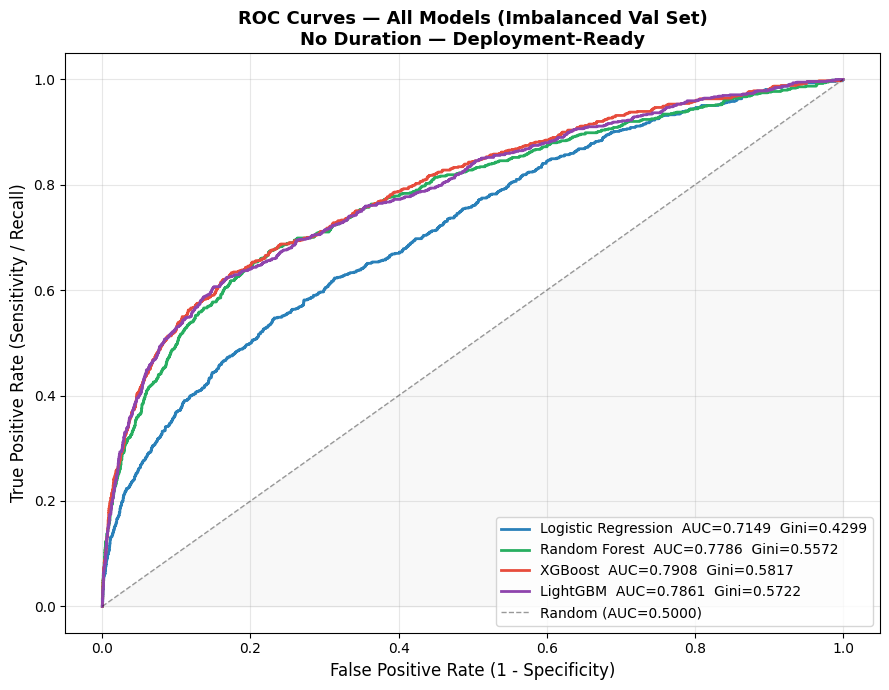

In [24]:
# ROC Curves — all models
plt.figure(figsize=(9, 7))
pal = ['#2980B9','#27AE60','#E74C3C','#8E44AD']

for (name, model), color in zip(trained_models.items(), pal):
    Xvl   = X_val_sc if "Logistic" in name else X_val
    proba = model.predict_proba(Xvl)[:,1]
    fpr, tpr, _ = roc_curve(y_val, proba)
    auc  = roc_auc_score(y_val, proba)
    gini = 2*auc-1
    plt.plot(fpr, tpr, color=color, lw=2,
             label=f"{name}  AUC={auc:.4f}  Gini={gini:.4f}")

plt.plot([0,1],[0,1],'k--',lw=1,alpha=0.4,label='Random (AUC=0.5000)')
plt.fill_between([0,1],[0,1],alpha=0.05,color='gray')
plt.xlabel("False Positive Rate (1 - Specificity)", fontsize=12)
plt.ylabel("True Positive Rate (Sensitivity / Recall)", fontsize=12)
plt.title("ROC Curves — All Models (Imbalanced Val Set)\nNo Duration — Deployment-Ready",
          fontsize=13, fontweight='bold')
plt.legend(loc='lower right', fontsize=10)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("08_roc_nodur.png", dpi=150, bbox_inches='tight')
plt.show()

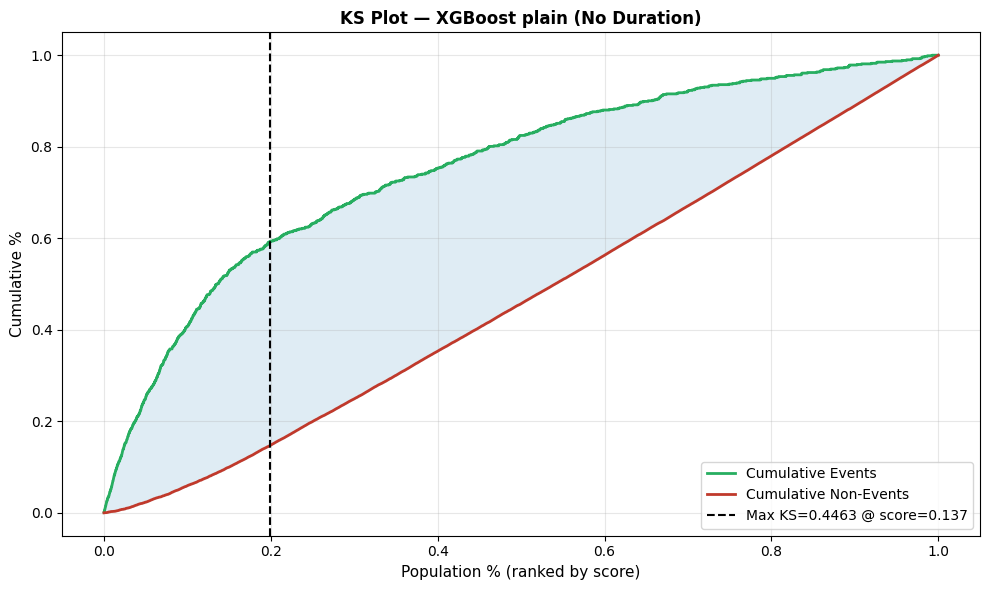

Max KS Statistic (XGBoost plain): 0.4463


In [25]:
# KS Plot — best model on test set
# 🔧 CHANGE #6: test_proba is the CALIBRATED final-model score defined in Section 6 (ranking identical to raw)

def ks_plot(y_true, y_score, model_name, ax=None):
    df_ks = pd.DataFrame({'score':y_score,'target':y_true})
    df_ks = df_ks.sort_values('score', ascending=False).reset_index(drop=True)
    n = len(df_ks)
    n_event    = df_ks['target'].sum()
    n_nonevent = n - n_event

    df_ks['cum_event']    = df_ks['target'].cumsum() / n_event
    df_ks['cum_nonevent'] = (1-df_ks['target']).cumsum() / n_nonevent
    df_ks['ks']           = df_ks['cum_event'] - df_ks['cum_nonevent']

    ks_max   = df_ks['ks'].max()
    ks_idx   = df_ks['ks'].idxmax()
    ks_score = df_ks.loc[ks_idx, 'score']

    if ax is None: fig, ax = plt.subplots(figsize=(10,6))
    x = np.linspace(0,1,n)
    ax.plot(x, df_ks['cum_event'],    color='#27AE60', lw=2, label='Cumulative Events')
    ax.plot(x, df_ks['cum_nonevent'], color='#C0392B', lw=2, label='Cumulative Non-Events')
    ax.fill_between(x, df_ks['cum_event'], df_ks['cum_nonevent'],
                    alpha=0.15, color='#2980B9')
    ax.axvline(ks_idx/n, color='black', ls='--', lw=1.5,
               label=f'Max KS={ks_max:.4f} @ score={ks_score:.3f}')
    ax.set_xlabel("Population % (ranked by score)", fontsize=11)
    ax.set_ylabel("Cumulative %", fontsize=11)
    ax.set_title(f"KS Plot — {model_name} (No Duration)", fontsize=12, fontweight='bold')
    ax.legend(); ax.grid(alpha=0.3)
    return ks_max, df_ks

fig, ax = plt.subplots(figsize=(10, 6))
ks_stat, df_ks_best = ks_plot(y_test.values, test_proba, best_name, ax)
plt.tight_layout()
plt.savefig("09_ks_plot_nodur.png", dpi=150, bbox_inches='tight')
plt.show()
print(f"Max KS Statistic ({best_name}): {ks_stat:.4f}")

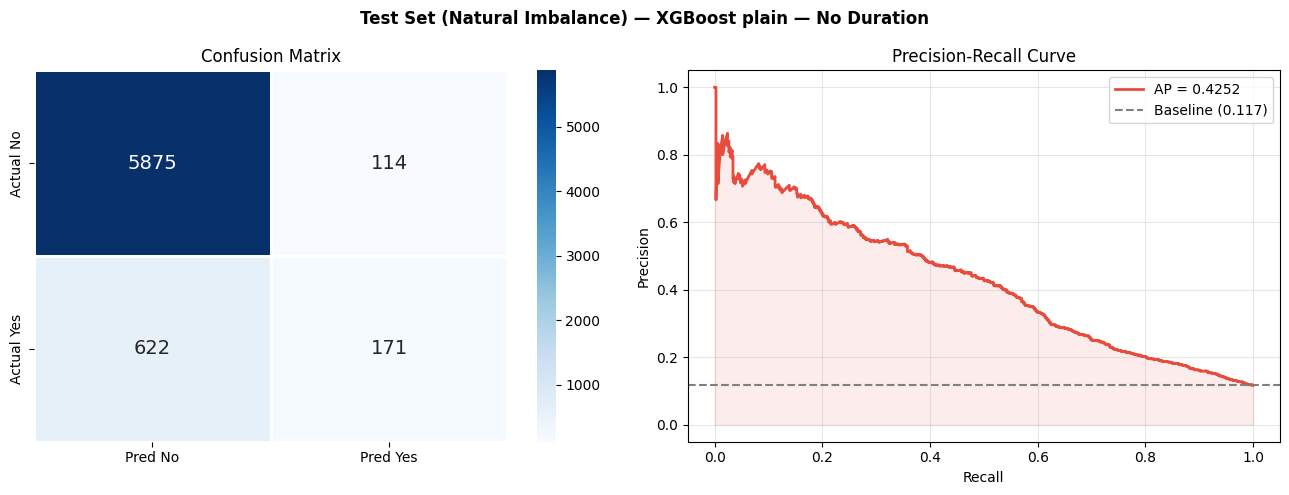

Test AUC  : 0.7880
Test Gini : 0.5760
Test KS   : 0.4463

              precision    recall  f1-score   support

          No       0.90      0.98      0.94      5989
         Yes       0.60      0.22      0.32       793

    accuracy                           0.89      6782
   macro avg       0.75      0.60      0.63      6782
weighted avg       0.87      0.89      0.87      6782



In [26]:
# Confusion Matrix + Precision-Recall Curve
# 0.5 is only a reference point here; the tuned threshold is chosen on validation in Section 9
test_pred = (test_proba >= 0.5).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle(f"Test Set (Natural Imbalance) — {best_name} — No Duration",
             fontsize=12, fontweight='bold')

cm = confusion_matrix(y_test, test_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Pred No','Pred Yes'],
            yticklabels=['Actual No','Actual Yes'],
            annot_kws={'size':14}, linewidths=1)
axes[0].set_title("Confusion Matrix")

prec_arr, rec_arr, _ = precision_recall_curve(y_test, test_proba)
ap = average_precision_score(y_test, test_proba)
axes[1].plot(rec_arr, prec_arr, color='#E74C3C', lw=2, label=f"AP = {ap:.4f}")
axes[1].axhline(y_test.mean(), color='gray', ls='--',
                label=f'Baseline ({y_test.mean():.3f})')
axes[1].fill_between(rec_arr, prec_arr, alpha=0.1, color='#E74C3C')
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall Curve")
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("10_cm_pr_nodur.png", dpi=150, bbox_inches='tight')
plt.show()

auc_test  = roc_auc_score(y_test, test_proba)
gini_test = 2*auc_test - 1
print(f"Test AUC  : {auc_test:.4f}")
print(f"Test Gini : {gini_test:.4f}")
print(f"Test KS   : {ks_stat:.4f}")
print()
print(classification_report(y_test, test_pred, target_names=['No','Yes']))

In [27]:
# Model Summary Table
summary_rows = []
for name, model in trained_models.items():
    Xts_m = X_test_sc if "Logistic" in name else X_test
    p  = model.predict_proba(Xts_m)[:,1]
    pr = (p >= 0.5).astype(int)
    auc   = roc_auc_score(y_test, p)
    fpr_m, tpr_m, _ = roc_curve(y_test, p)
    ks_m  = float(np.max(tpr_m - fpr_m))
    summary_rows.append({
        'Model'    : name,
        'AUC'      : round(auc,4),
        'Gini'     : round(2*auc-1,4),
        'KS'       : round(ks_m,4),
        'F1'       : round(f1_score(y_test,pr),4),
        'Precision': round(precision_score(y_test,pr),4),
        'Recall'   : round(recall_score(y_test,pr),4),
    })

summary_df = pd.DataFrame(summary_rows).sort_values('AUC', ascending=False)
print("Model Comparison (Test Set — No Duration — Natural Imbalanced Distribution):")
print(summary_df.to_string(index=False))

Model Comparison (Test Set — No Duration — Natural Imbalanced Distribution):
              Model    AUC   Gini     KS     F1  Precision  Recall
            XGBoost 0.7765 0.5530 0.4337 0.3630     0.5441  0.2724
           LightGBM 0.7719 0.5439 0.4255 0.3601     0.5462  0.2686
      Random Forest 0.7699 0.5398 0.4280 0.4158     0.3864  0.4502
Logistic Regression 0.6959 0.3918 0.2879 0.3254     0.3771  0.2863


## Section 8: Decile Analysis — KS Decile, Rank-over-Break, Lift

**Why Decile Analysis matters for campaign management:**  
- Bank calls agents have a finite capacity — they cannot call all 45K customers
- Decile analysis tells the business: "If we can call the top X% of customers, what % of subscribers will we reach?"
- **Rank-over-Break (RoB)** = how much better than random is this decile?
- Top-3 decile capture = the % of all potential subscribers the bank can reach by calling only 30% of customers

*Evaluated on natural imbalanced test set to reflect real-world campaign performance.*

In [28]:
def decile_analysis(y_true, y_score, n_deciles=10):
    df_d = pd.DataFrame({'score':y_score, 'target':y_true}).copy()
    df_d = df_d.sort_values('score', ascending=False).reset_index(drop=True)
    df_d['decile'] = pd.qcut(df_d.index, q=n_deciles, labels=range(1, n_deciles+1))

    total_event    = df_d['target'].sum()
    total_nonevent = len(df_d) - total_event
    overall_rate   = df_d['target'].mean()

    rows = []
    for d in range(1, n_deciles+1):
        grp      = df_d[df_d['decile']==d]
        n        = len(grp)
        events   = grp['target'].sum()
        nonevents= n - events
        conv     = events / n
        rob      = conv / overall_rate

        rows.append({
            'Decile'         : d,
            'N'              : n,
            'Events'         : events,
            'Non_Events'     : nonevents,
            'Score_Min'      : grp['score'].min(),
            'Score_Max'      : grp['score'].max(),
            'Score_Avg'      : grp['score'].mean(),
            'Conversion_Rate': conv,
            'Rank_over_Break': rob,
        })

    dec_df = pd.DataFrame(rows)
    dec_df['Cum_Events']       = dec_df['Events'].cumsum()
    dec_df['Cum_NonEvents']    = dec_df['Non_Events'].cumsum()
    dec_df['Cum_Event_Pct']    = dec_df['Cum_Events']    / total_event
    dec_df['Cum_NonEvent_Pct'] = dec_df['Cum_NonEvents'] / total_nonevent
    dec_df['KS']               = dec_df['Cum_Event_Pct'] - dec_df['Cum_NonEvent_Pct']

    max_ks_decile = dec_df.loc[dec_df['KS'].idxmax(), 'Decile']
    max_ks_value  = dec_df['KS'].max()
    top3_events   = dec_df[dec_df['Decile'] <= 3]['Events'].sum()
    top3_conv_pct = top3_events / total_event * 100

    return dec_df, max_ks_decile, max_ks_value, top3_conv_pct

dec_table, max_ks_dec, max_ks_val, top3_pct = decile_analysis(
    y_test.values, test_proba)

print(f"Decile Analysis — {best_name}  (No Duration — Natural Imbalanced Test Set)")
print(f"  Max KS Value       : {max_ks_val:.4f}")
print(f"  Max KS Decile      : Decile {max_ks_dec}")
print(f"  Top-3 Decile Conv  : {top3_pct:.1f}% of all subscribers in top 30% of customers")
print()

display_cols = ['Decile','N','Events','Non_Events',
                'Score_Min','Score_Max','Conversion_Rate',
                'Rank_over_Break','Cum_Event_Pct','Cum_NonEvent_Pct','KS']
print(dec_table[display_cols].to_string(index=False))

Decile Analysis — XGBoost plain  (No Duration — Natural Imbalanced Test Set)
  Max KS Value       : 0.4460
  Max KS Decile      : Decile 2
  Top-3 Decile Conv  : 68.5% of all subscribers in top 30% of customers

 Decile   N  Events  Non_Events  Score_Min  Score_Max  Conversion_Rate  Rank_over_Break  Cum_Event_Pct  Cum_NonEvent_Pct     KS
      1 679     323         356     0.2878     0.9449           0.4757           4.0683         0.4073            0.0594 0.3479
      2 678     148         530     0.1363     0.2876           0.2183           1.8669         0.5939            0.1479 0.4460
      3 678      72         606     0.0992     0.1362           0.1062           0.9082         0.6847            0.2491 0.4356
      4 678      54         624     0.0806     0.0991           0.0796           0.6812         0.7528            0.3533 0.3995
      5 678      57         621     0.0667     0.0806           0.0841           0.7190         0.8247            0.4570 0.3677
      6 678      44 

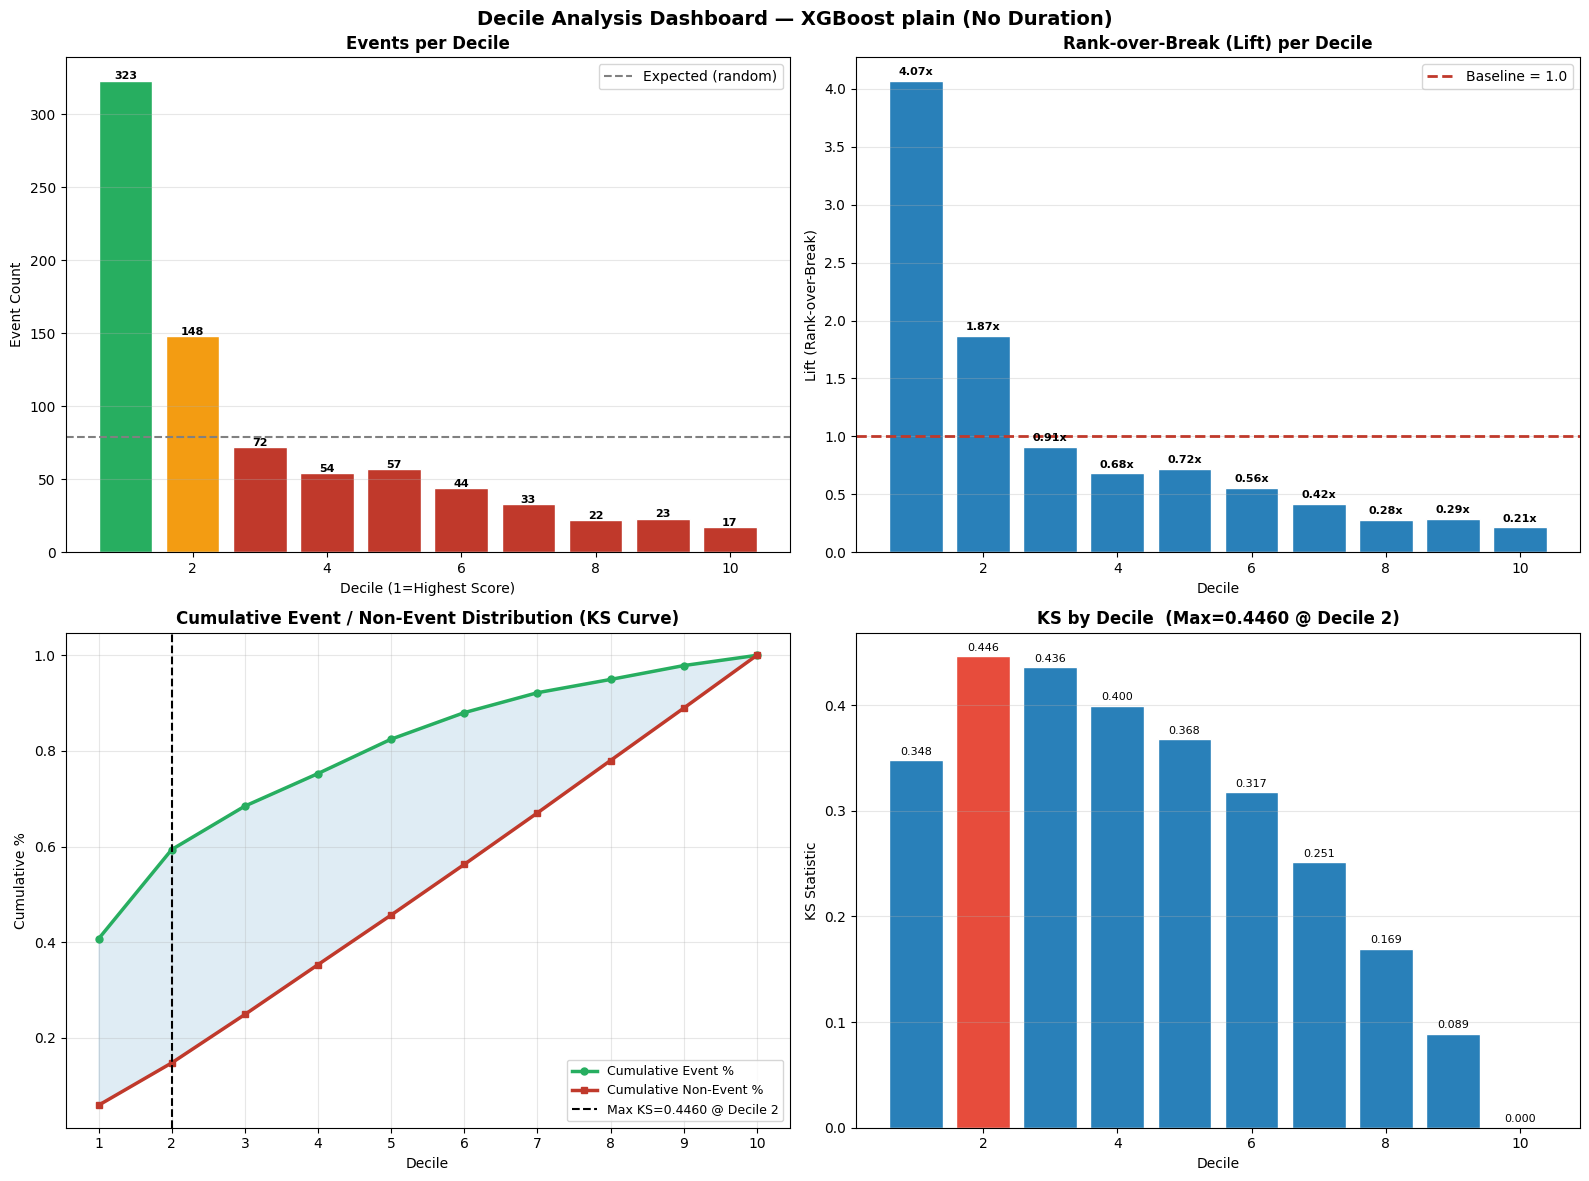

In [29]:
# Decile Charts — 4 panels
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle(f"Decile Analysis Dashboard — {best_name} (No Duration)",
             fontsize=14, fontweight='bold')

dec = dec_table.copy()

# Panel 1: Events per Decile
ax1 = axes[0][0]
bar_colors = ['#27AE60' if rob>=2 else '#F39C12' if rob>=1 else '#C0392B'
              for rob in dec['Rank_over_Break']]
bars = ax1.bar(dec['Decile'], dec['Events'], color=bar_colors, edgecolor='white')
ax1.axhline(dec['Events'].mean(), color='gray', ls='--', label='Expected (random)')
ax1.set_title("Events per Decile", fontweight='bold')
ax1.set_xlabel("Decile (1=Highest Score)"); ax1.set_ylabel("Event Count")
ax1.legend(); ax1.grid(axis='y', alpha=0.3)
for b, v in zip(bars, dec['Events']):
    ax1.text(b.get_x()+b.get_width()/2, v+1, str(int(v)),
             ha='center', fontsize=8, fontweight='bold')

# Panel 2: Rank-over-Break
ax2 = axes[0][1]
ax2.bar(dec['Decile'], dec['Rank_over_Break'], color='#2980B9', edgecolor='white')
ax2.axhline(1.0, color='#C0392B', ls='--', lw=2, label='Baseline = 1.0')
ax2.set_title("Rank-over-Break (Lift) per Decile", fontweight='bold')
ax2.set_xlabel("Decile"); ax2.set_ylabel("Lift (Rank-over-Break)")
ax2.legend(); ax2.grid(axis='y', alpha=0.3)
for i, (_, row) in enumerate(dec.iterrows()):
    ax2.text(row['Decile'], row['Rank_over_Break']+0.05,
             f"{row['Rank_over_Break']:.2f}x", ha='center', fontsize=8, fontweight='bold')

# Panel 3: KS Cumulative
ax3 = axes[1][0]
ax3.plot(dec['Cum_Event_Pct'],    color='#27AE60', lw=2.5, marker='o', ms=5, label='Cumulative Event %')
ax3.plot(dec['Cum_NonEvent_Pct'], color='#C0392B', lw=2.5, marker='s', ms=5, label='Cumulative Non-Event %')
ax3.fill_between(range(len(dec)), dec['Cum_Event_Pct'], dec['Cum_NonEvent_Pct'],
                 alpha=0.15, color='#2980B9')
ax3.set_xticks(range(len(dec))); ax3.set_xticklabels(dec['Decile'])
ax3.axvline(dec['KS'].idxmax(), color='black', ls='--', lw=1.5,
            label=f'Max KS={max_ks_val:.4f} @ Decile {max_ks_dec}')
ax3.set_title("Cumulative Event / Non-Event Distribution (KS Curve)", fontweight='bold')
ax3.set_xlabel("Decile"); ax3.set_ylabel("Cumulative %")
ax3.legend(fontsize=9); ax3.grid(alpha=0.3)

# Panel 4: KS by Decile
ax4 = axes[1][1]
ks_colors = ['#E74C3C' if d==max_ks_dec else '#2980B9' for d in dec['Decile']]
ax4.bar(dec['Decile'], dec['KS'], color=ks_colors, edgecolor='white')
ax4.set_title(f"KS by Decile  (Max={max_ks_val:.4f} @ Decile {max_ks_dec})", fontweight='bold')
ax4.set_xlabel("Decile"); ax4.set_ylabel("KS Statistic")
ax4.grid(axis='y', alpha=0.3)
for _, row in dec.iterrows():
    ax4.text(row['Decile'], row['KS']+0.005, f"{row['KS']:.3f}",
             ha='center', fontsize=8)

plt.tight_layout()
plt.savefig("11_decile_dashboard_nodur.png", dpi=150, bbox_inches='tight')
plt.show()

In [30]:
# 🔧 CHANGE #9: report BOTH sides of the trade-off (contacts saved AND subscribers missed)
# Top-3 Decile Summary + Business Interpretation
top3        = dec_table[dec_table['Decile'] <= 3]
total_events= dec_table['Events'].sum()

print("=" * 60)
print("TOP-3 DECILE CONVERSION ANALYSIS — BUSINESS IMPACT")
print("=" * 60)
print(f"  Total subscribers in test set  : {total_events:,}")
print(f"  Subscribers in top 3 deciles   : {top3['Events'].sum():,}")
print(f"  Top-3 Decile Capture Rate      : {top3_pct:.1f}%")
print(f"  Avg Conversion in top 3 deciles: {top3['Conversion_Rate'].mean()*100:.1f}%")
print(f"  Overall Conversion Rate        : {dec_table['Conversion_Rate'].mean()*100:.1f}%")
print()
print("By Decile:")
print(top3[['Decile','N','Events','Conversion_Rate','Rank_over_Break']].to_string(index=False))
print()
n_test      = len(y_test)
contacted   = top3['N'].sum() / n_test * 100
print("Business Interpretation:")
print(f"  -> Calling the top 30% of customers reaches {top3_pct:.0f}% of all subscribers")
print(f"  -> Contacts avoided: {100-contacted:.0f}%   |   Subscribers missed: {100-top3_pct:.0f}%")
print("  -> This is a trade-off, not free savings: the right cut-off depends on cost per call vs value per subscriber (Section 9).")

TOP-3 DECILE CONVERSION ANALYSIS — BUSINESS IMPACT
  Total subscribers in test set  : 793
  Subscribers in top 3 deciles   : 543
  Top-3 Decile Capture Rate      : 68.5%
  Avg Conversion in top 3 deciles: 26.7%
  Overall Conversion Rate        : 11.7%

By Decile:
 Decile   N  Events  Conversion_Rate  Rank_over_Break
      1 679     323           0.4757           4.0683
      2 678     148           0.2183           1.8669
      3 678      72           0.1062           0.9082

Business Interpretation:
  -> Calling the top 30% of customers reaches 68% of all subscribers
  -> Contacts avoided: 70%   |   Subscribers missed: 32%
  -> This is a trade-off, not free savings: the right cut-off depends on cost per call vs value per subscriber (Section 9).


## Section 9: Threshold Tuning — Business Cost-Aware

> 🔧 **CHANGE #1:** every threshold below is chosen on the **validation** set. The **test** set is used once, to report.

- **False Negative (FN):** missing a subscriber -> lost revenue (high cost)
- **False Positive (FP):** calling a non-subscriber -> wasted agent time (low cost)

With *calibrated* probabilities the cost-optimal threshold has a closed form: `cost_FP / (cost_FP + cost_FN)`.
The sweep below should land close to it — a useful sanity check.

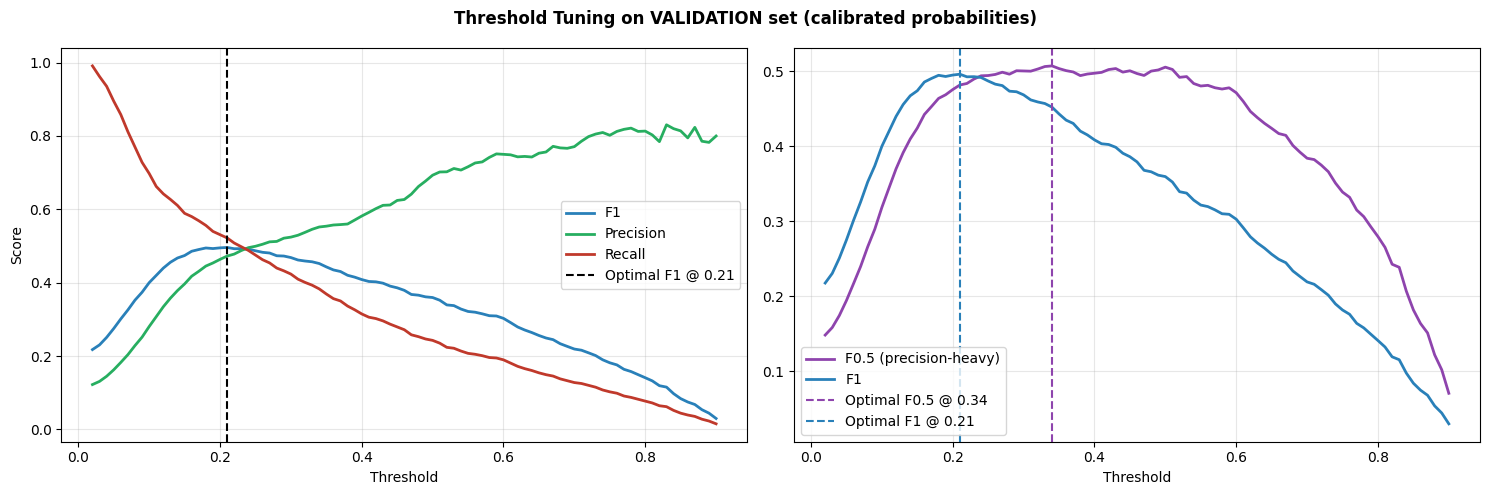

Threshold chosen on VALIDATION (F1-optimal): 0.21
TEST performance at that threshold (test never used for tuning):
              precision    recall  f1-score   support

          No       0.93      0.91      0.92      5989
         Yes       0.43      0.50      0.46       793

    accuracy                           0.86      6782
   macro avg       0.68      0.71      0.69      6782
weighted avg       0.87      0.86      0.87      6782



In [31]:
# 🔧 CHANGE #1: sweep on VALIDATION (val_proba / y_val), report on TEST
thresholds = np.arange(0.02, 0.91, 0.01)
f1s, precs, recs, f05s = [], [], [], []

for t in thresholds:
    pred = (val_proba >= t).astype(int)
    f1s.append(f1_score(y_val, pred, zero_division=0))
    precs.append(precision_score(y_val, pred, zero_division=0))
    recs.append(recall_score(y_val, pred, zero_division=0))
    p, r, b = precs[-1], recs[-1], 0.5
    f05s.append((1 + b**2) * p * r / max(b**2 * p + r, 1e-9))

opt_thr_f1  = thresholds[int(np.argmax(f1s))]
opt_thr_f05 = thresholds[int(np.argmax(f05s))]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle("Threshold Tuning on VALIDATION set (calibrated probabilities)", fontsize=12, fontweight='bold')
axes[0].plot(thresholds, f1s,   color='#2980B9', lw=2, label='F1')
axes[0].plot(thresholds, precs, color='#27AE60', lw=2, label='Precision')
axes[0].plot(thresholds, recs,  color='#C0392B', lw=2, label='Recall')
axes[0].axvline(opt_thr_f1, color='black', ls='--', label=f'Optimal F1 @ {opt_thr_f1:.2f}')
axes[0].set_xlabel("Threshold"); axes[0].set_ylabel("Score"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(thresholds, f05s, color='#8E44AD', lw=2, label='F0.5 (precision-heavy)')
axes[1].plot(thresholds, f1s,  color='#2980B9', lw=2, label='F1')
axes[1].axvline(opt_thr_f05, color='#8E44AD', ls='--', label=f'Optimal F0.5 @ {opt_thr_f05:.2f}')
axes[1].axvline(opt_thr_f1,  color='#2980B9', ls='--', label=f'Optimal F1 @ {opt_thr_f1:.2f}')
axes[1].set_xlabel("Threshold"); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.savefig("17_threshold_nodur.png", dpi=150, bbox_inches='tight'); plt.show()

opt_thr    = opt_thr_f1
final_pred = (test_proba >= opt_thr).astype(int)
print(f"Threshold chosen on VALIDATION (F1-optimal): {opt_thr:.2f}")
print("TEST performance at that threshold (test never used for tuning):")
print(classification_report(y_test, final_pred, target_names=['No', 'Yes']))

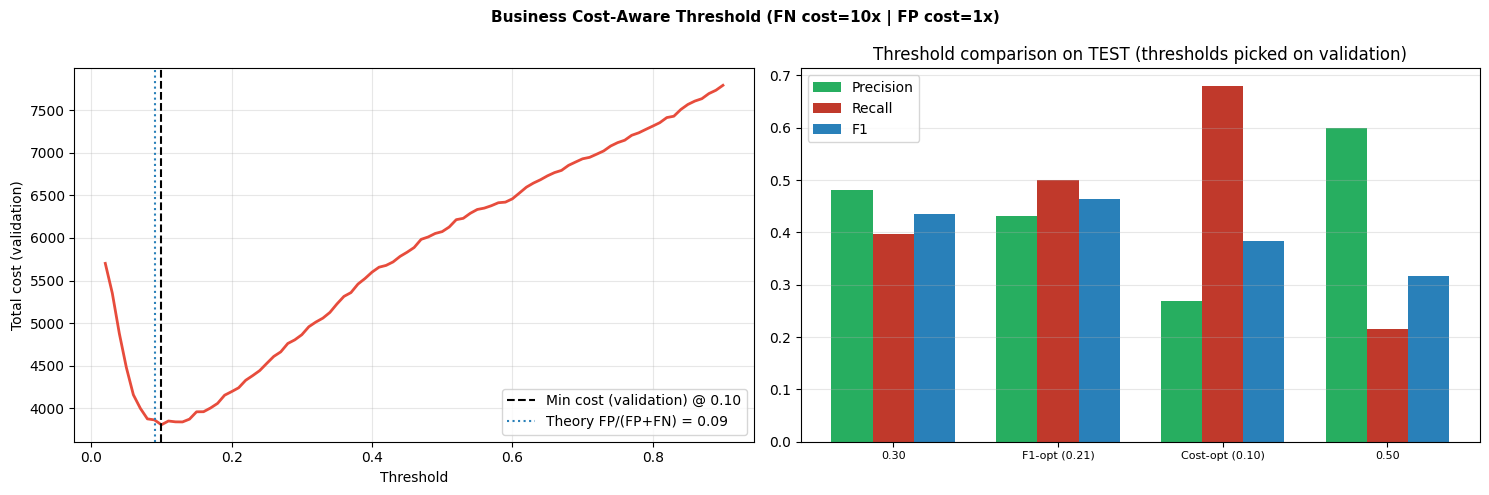

 Threshold  Precision  Recall     F1   FP  FN  Total_Cost(test)
    0.3000     0.4817  0.3972 0.4354  339 478              5119
    0.2100     0.4318  0.4994 0.4632  521 397              4491
    0.1000     0.2680  0.6797 0.3845 1472 254              4012
    0.5000     0.6000  0.2156 0.3173  114 622              6334

Recommended threshold for deployment: 0.10 (min business cost, chosen on validation)
Alternative: 0.21 (max F1) if the cost ratio is unknown


In [32]:
# 🔧 CHANGE #1 / #6: cost curve on VALIDATION; comparison table on TEST
COST_FN = 10   # lost term-deposit revenue (units) — change to your bank's economics
COST_FP = 1    # wasted agent call (units)

def cost_at(y_true, proba, t):
    pred = (proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return fn * COST_FN + fp * COST_FP, fp, fn, tp

val_cost     = [cost_at(y_val, val_proba, t)[0] for t in thresholds]
opt_thr_cost = float(thresholds[int(np.argmin(val_cost))])
theory_thr   = COST_FP / (COST_FP + COST_FN)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle(f"Business Cost-Aware Threshold (FN cost={COST_FN}x | FP cost={COST_FP}x)", fontsize=11, fontweight='bold')
axes[0].plot(thresholds, val_cost, color='#E74C3C', lw=2)
axes[0].axvline(opt_thr_cost, color='black', ls='--', label=f'Min cost (validation) @ {opt_thr_cost:.2f}')
axes[0].axvline(theory_thr,  color='#2980B9', ls=':', label=f'Theory FP/(FP+FN) = {theory_thr:.2f}')
axes[0].set_xlabel("Threshold"); axes[0].set_ylabel("Total cost (validation)"); axes[0].legend(); axes[0].grid(alpha=0.3)

compare_thrs = [0.30, opt_thr_f1, opt_thr_cost, 0.50]
compare_lbls = ['0.30', f'F1-opt ({opt_thr_f1:.2f})', f'Cost-opt ({opt_thr_cost:.2f})', '0.50']
rows = []
for t in compare_thrs:
    c, fp, fn, tp = cost_at(y_test, test_proba, t)
    pred = (test_proba >= t).astype(int)
    rows.append({'Threshold': t, 'Precision': precision_score(y_test, pred, zero_division=0),
                 'Recall': recall_score(y_test, pred, zero_division=0), 'F1': f1_score(y_test, pred, zero_division=0),
                 'FP': fp, 'FN': fn, 'Total_Cost(test)': c})
mc_df = pd.DataFrame(rows)
x, w = np.arange(len(compare_thrs)), 0.25
axes[1].bar(x - w, mc_df['Precision'], w, label='Precision', color='#27AE60')
axes[1].bar(x,     mc_df['Recall'],    w, label='Recall',    color='#C0392B')
axes[1].bar(x + w, mc_df['F1'],        w, label='F1',        color='#2980B9')
axes[1].set_xticks(x); axes[1].set_xticklabels(compare_lbls, fontsize=8)
axes[1].set_title("Threshold comparison on TEST (thresholds picked on validation)"); axes[1].legend(); axes[1].grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.savefig("17b_cost_threshold_nodur.png", dpi=150, bbox_inches='tight'); plt.show()

print(mc_df.round(4).to_string(index=False))
print(f"\nRecommended threshold for deployment: {opt_thr_cost:.2f} (min business cost, chosen on validation)")
print(f"Alternative: {opt_thr_f1:.2f} (max F1) if the cost ratio is unknown")

## Section 10: Stability — PSI + Chronological Out-of-Time Test

> 🔧 **CHANGE #3**

**v1 claimed an out-of-time check but used a random split**, so PSI ~0.001 was true by construction (both samples
come from the same distribution). Two checks now:

1. **Random-split PSI** (validation vs test scores): a *sanity check only* — expect ~0.
2. **Out-of-time (OOT) test**: the UCI file is ordered by date (May 2008 -> Nov 2010). Train on the **first 70%**,
   test on the **last 30%**. This is the realistic question: *does a model trained on the past still work on the future?*

| PSI | Meaning |
|---|---|
| < 0.10 | Stable |
| 0.10 – 0.25 | Some shift — monitor |
| > 0.25 | Major shift — retrain |

Expect a real drop: the later part of this campaign has a different month mix and a higher subscription rate.
Report it honestly — that is the point.

In [33]:
# 🔧 CHANGE #3: PSI function unchanged; usage below is new
def compute_psi(expected_scores, actual_scores, buckets=10):
    breakpoints = np.percentile(expected_scores, np.linspace(0, 100, buckets+1))
    breakpoints = np.unique(breakpoints)

    def get_bucket_counts(scores, bp):
        counts = np.zeros(len(bp)-1)
        for i in range(len(bp)-1):
            lo, hi = bp[i], bp[i+1]
            if i == 0:
                counts[i] = ((scores >= lo) & (scores <= hi)).sum()
            else:
                counts[i] = ((scores > lo)  & (scores <= hi)).sum()
        return counts

    exp_counts = get_bucket_counts(expected_scores, breakpoints)
    act_counts = get_bucket_counts(actual_scores,   breakpoints)

    exp_pct = (exp_counts / len(expected_scores)).clip(1e-6)
    act_pct = (act_counts / len(actual_scores)).clip(1e-6)
    psi_bins = (act_pct - exp_pct) * np.log(act_pct / exp_pct)

    psi_df = pd.DataFrame({
        'Bucket'       : range(1, len(psi_bins)+1),
        'Score_Low'    : breakpoints[:-1],
        'Score_High'   : breakpoints[1:],
        'Expected_Pct' : exp_pct,
        'Actual_Pct'   : act_pct,
        'PSI_Bin'      : psi_bins
    })
    return psi_bins.sum(), psi_df

# (1) Random split: validation scores vs test scores — a sanity check, ~0 by construction
psi_val, psi_df = compute_psi(val_proba, test_proba)

def psi_label(p):
    if p < 0.10: return "STABLE — No Action Needed"
    elif p < 0.25: return "MONITOR — Some Shift Detected"
    else: return "ALERT — Model Retraining Recommended"

print(f"PSI (random split, val vs test): {psi_val:.4f}  [{psi_label(psi_val)}]  <- trivially stable, same distribution")

PSI (random split, val vs test): 0.0014  [STABLE — No Action Needed]  <- trivially stable, same distribution


In [34]:
# 🔧 CHANGE #3: chronological out-of-time test (rows of bank-full.csv are in date order)
n_all = len(df_model)
cut   = int(n_all * 0.70)
dev, oot = df_model.iloc[:cut], df_model.iloc[cut:]
X_dev, y_dev = dev[FEATURES], dev[TARGET]
X_oot, y_oot = oot[FEATURES], oot[TARGET]

# hold out 20% of the PAST (random) to act as the "expected" score distribution
X_fit, X_hold, y_fit, y_hold = train_test_split(X_dev, y_dev, test_size=0.20, stratify=y_dev, random_state=101)
m_oot = fit_xgb(X_fit, y_fit, FINAL_STRATEGY)          # same recipe as the final model
hold_scores = m_oot.predict_proba(X_hold)[:, 1]
oot_scores  = m_oot.predict_proba(X_oot)[:, 1]

auc_hold = roc_auc_score(y_hold, hold_scores)
auc_oot  = roc_auc_score(y_oot,  oot_scores)
psi_oot, psi_df_oot = compute_psi(hold_scores, oot_scores)
_, _, _, top3_oot = decile_analysis(y_oot.values, oot_scores)

print(f"{'':28}{'Past (random hold-out)':>24}{'Future (last 30%)':>20}")
print(f"{'Rows':28}{len(y_hold):>24,}{len(y_oot):>20,}")
print(f"{'Event rate':28}{y_hold.mean()*100:>23.1f}%{y_oot.mean()*100:>19.1f}%")
print(f"{'AUC':28}{auc_hold:>24.4f}{auc_oot:>20.4f}")
print(f"\nAUC drop (past -> future): {auc_hold - auc_oot:+.4f}")
print(f"Top-3 decile capture on OOT: {top3_oot:.1f}%")
print(f"PSI (past vs future scores): {psi_oot:.4f}  [{psi_label(psi_oot)}]")
print("\nNote: OOT scores are on RAW model output (no calibration) — PSI and AUC are rank/shape based, so this is fine.")

                              Past (random hold-out)   Future (last 30%)
Rows                                           6,330              13,564
Event rate                                      5.8%               25.4%
AUC                                           0.6589              0.6752

AUC drop (past -> future): -0.0163
Top-3 decile capture on OOT: 46.7%
PSI (past vs future scores): 0.2496  [MONITOR — Some Shift Detected]

Note: OOT scores are on RAW model output (no calibration) — PSI and AUC are rank/shape based, so this is fine.


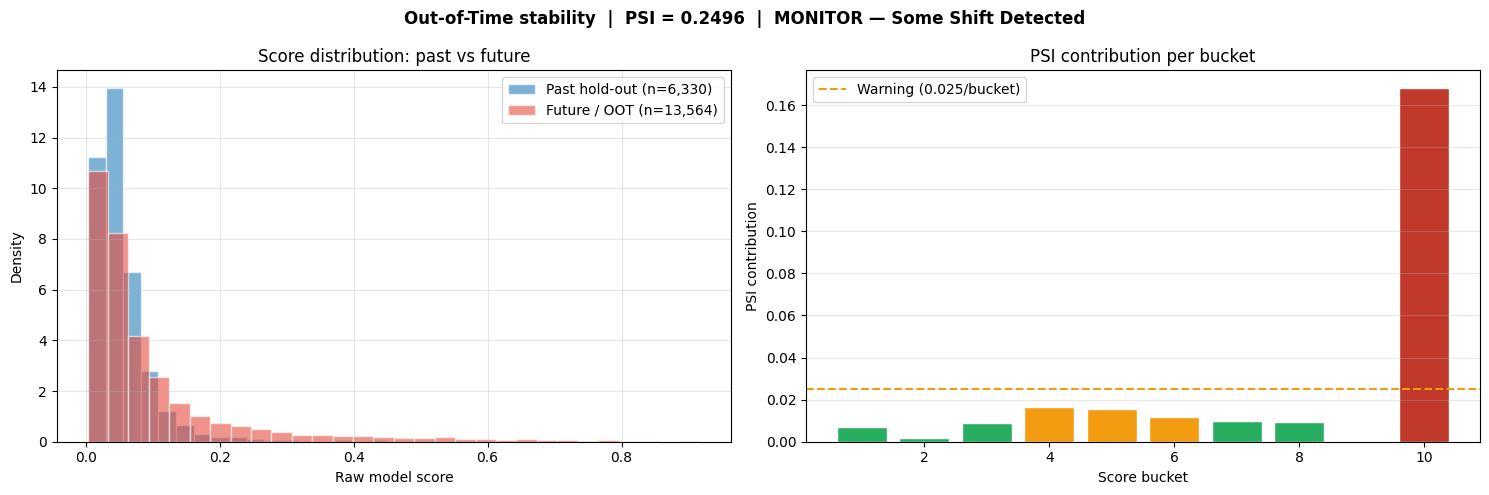

In [35]:
# 🔧 CHANGE #3: PSI visualisation — out-of-time
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle(f"Out-of-Time stability  |  PSI = {psi_oot:.4f}  |  {psi_label(psi_oot)}", fontsize=12, fontweight='bold')
axes[0].hist(hold_scores, bins=30, alpha=0.6, density=True, color='#2980B9', label=f'Past hold-out (n={len(hold_scores):,})', edgecolor='white')
axes[0].hist(oot_scores,  bins=30, alpha=0.6, density=True, color='#E74C3C', label=f'Future / OOT (n={len(oot_scores):,})', edgecolor='white')
axes[0].set_xlabel("Raw model score"); axes[0].set_ylabel("Density"); axes[0].set_title("Score distribution: past vs future")
axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].bar(psi_df_oot['Bucket'], psi_df_oot['PSI_Bin'],
            color=['#C0392B' if v > 0.025 else '#F39C12' if v > 0.01 else '#27AE60' for v in psi_df_oot['PSI_Bin']], edgecolor='white')
axes[1].axhline(0.025, color='#F39C12', ls='--', lw=1.5, label='Warning (0.025/bucket)')
axes[1].set_xlabel("Score bucket"); axes[1].set_ylabel("PSI contribution"); axes[1].set_title("PSI contribution per bucket")
axes[1].legend(); axes[1].grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.savefig("18_psi_oot.png", dpi=150, bbox_inches='tight'); plt.show()

## Section 11: SHAP Explainability + Model Scorecard Summary + Duration vs No-Duration Comparison

**Final section: the complete banking scorecard and a head-to-head comparison.**

This comparison is critical for business stakeholders — it shows:
1. How much performance we sacrifice by removing duration
2. Why that sacrifice is worth it for deployability
3. What the honest, real-world performance of the pre-call model is

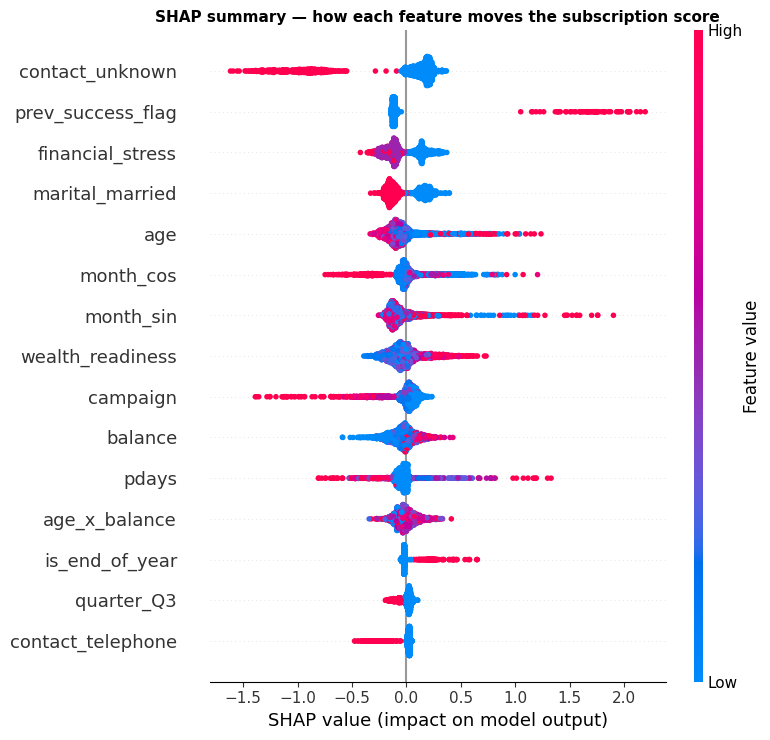

Top-10 features by mean |SHAP| (log-odds):
contact_unknown     0.4026
prev_success_flag   0.1727
financial_stress    0.1533
marital_married     0.1524
age                 0.1381
month_cos           0.1330
month_sin           0.1325
wealth_readiness    0.1153
campaign            0.1022
balance             0.0891


In [36]:
# 🔧 CHANGE #8: SHAP — which features drive the model, and in which direction?
import shap
try:
    explainer = shap.TreeExplainer(final_model)
    shap_sample = X_test.sample(min(2000, len(X_test)), random_state=1)
    sv = explainer.shap_values(shap_sample)
    sv = sv[1] if isinstance(sv, list) else sv

    plt.figure(); shap.summary_plot(sv, shap_sample, show=False, max_display=15)
    plt.title("SHAP summary — how each feature moves the subscription score", fontsize=11, fontweight='bold')
    plt.tight_layout(); plt.savefig("13_shap_beeswarm.png", dpi=150, bbox_inches='tight'); plt.show()

    shap_top = pd.Series(np.abs(sv).mean(0), index=shap_sample.columns).sort_values(ascending=False).head(10)
    print("Top-10 features by mean |SHAP| (log-odds):")
    print(shap_top.round(4).to_string())
except Exception as e:
    print("SHAP skipped:", e)

**How to read it (write 3 bullets in your README from your own output):** each dot is a customer; right = pushes the score up.
Colour = feature value (red high / blue low). Look for: which contact-related and prior-outcome features dominate, whether
`month` effects are large (campaign-specific, may not transfer to another bank), and whether balance/age behave monotonically.

In [37]:
# 🔧 CHANGE #1/#3/#6: scorecard reads validation-tuned threshold, calibrated scores and OOT stability
# Full Banking Scorecard Report — No Duration
auc_final   = roc_auc_score(y_test, test_proba)
gini_final  = 2 * auc_final - 1
fpr_f, tpr_f, _ = roc_curve(y_test, test_proba)
ks_final    = float(np.max(tpr_f - fpr_f))

final_pred_sc = (test_proba >= opt_thr).astype(int)
f1_final    = f1_score(y_test, final_pred_sc)
prec_final  = precision_score(y_test, final_pred_sc)
rec_final   = recall_score(y_test, final_pred_sc)

print("=" * 65)
print("   TERM DEPOSIT PROPENSITY MODEL — SCORECARD REPORT")
print("   (NO DURATION — DEPLOYMENT READY)")
print("=" * 65)
print(f"  Model Name         : {best_name}  (calibrated)")
print(f"  Dataset            : UCI Bank Marketing Full (45,211 records)")
print(f"  Imbalance Handling : {best_name} (chosen on validation)")
print(f"  Duration Feature   : EXCLUDED (data leakage prevention)")
print(f"  Test Set Size      : {len(y_test):,} records  (natural imbalanced distribution)")
print()
print("  --- DISCRIMINATION METRICS ---")
print(f"  AUC-ROC            : {auc_final:.4f}")
print(f"  Gini Coefficient   : {gini_final:.4f}  (2xAUC - 1)")
print(f"  KS Statistic       : {ks_final:.4f}")
print(f"  Max KS Decile      : Decile {max_ks_dec}")
print()
print(f"  --- CLASSIFICATION METRICS (threshold={opt_thr:.2f}, tuned on validation) ---")
print(f"  F1 Score           : {f1_final:.4f}")
print(f"  Precision          : {prec_final:.4f}")
print(f"  Recall             : {rec_final:.4f}")
print()
print("  --- DECILE PERFORMANCE ---")
print(f"  Top-3 Decile Capture: {top3_pct:.1f}% of all subscribers")
print(f"  Top-1 Decile RoB    : {dec_table.iloc[0]['Rank_over_Break']:.2f}x baseline")
print()
print("  --- STABILITY (CHANGE #3) ---")
print(f"  PSI random split (sanity)   : {psi_val:.4f}")
print(f"  PSI out-of-time             : {psi_oot:.4f}  [{psi_label(psi_oot)}]")
print(f"  AUC out-of-time (future)    : {auc_oot:.4f}")
print()
print("  --- IV SUMMARY (Top 5 Pre-Call Features) ---")
for _, row in iv_df.head(5).iterrows():
    print(f"  {row['feature']:<20}: IV={row['IV']:.4f}  ({row['Predictive_Power']})")
print("=" * 65)

   TERM DEPOSIT PROPENSITY MODEL — SCORECARD REPORT
   (NO DURATION — DEPLOYMENT READY)
  Model Name         : XGBoost plain  (calibrated)
  Dataset            : UCI Bank Marketing Full (45,211 records)
  Imbalance Handling : XGBoost plain (chosen on validation)
  Duration Feature   : EXCLUDED (data leakage prevention)
  Test Set Size      : 6,782 records  (natural imbalanced distribution)

  --- DISCRIMINATION METRICS ---
  AUC-ROC            : 0.7880
  Gini Coefficient   : 0.5760  (2xAUC - 1)
  KS Statistic       : 0.4463
  Max KS Decile      : Decile 2

  --- CLASSIFICATION METRICS (threshold=0.21, tuned on validation) ---
  F1 Score           : 0.4632
  Precision          : 0.4318
  Recall             : 0.4994

  --- DECILE PERFORMANCE ---
  Top-3 Decile Capture: 68.5% of all subscribers
  Top-1 Decile RoB    : 4.07x baseline

  --- STABILITY (CHANGE #3) ---
  PSI random split (sanity)   : 0.0014
  PSI out-of-time             : 0.2496  [MONITOR — Some Shift Detected]
  AUC out-of-t

In [38]:
# 🔧 CHANGE #9: duration-model numbers are hardcoded from the earlier run — labelled as such
# Duration vs No-Duration Comparison Table
print("=" * 75)
print("   DURATION vs NO-DURATION MODEL — HEAD-TO-HEAD COMPARISON")
print("=" * 75)
comparison = {
    'Metric'              : ['AUC-ROC', 'Gini', 'KS Statistic', 'F1 Score',
                             'Precision', 'Recall',
                             'Top-3 Decile Capture', 'PSI (out-of-time)',
                             'Max KS Decile', 'Deployable?', 'Data Leakage?'],
    'With Duration (prior run, hardcoded)'       : ['0.9166', '0.8332', '0.7038', '0.5965',
                             '0.5233', '0.6936',
                             '90.7%', '4.1787 [ALERT]',
                             'Decile 3', '❌ NO', '✅ YES (duration leaked)'],
    'No Duration (This)'  : [
        f'{auc_final:.4f}', f'{gini_final:.4f}', f'{ks_final:.4f}', f'{f1_final:.4f}',
        f'{prec_final:.4f}', f'{rec_final:.4f}',
        f'{top3_pct:.1f}%',
        f'{psi_oot:.4f} [{psi_label(psi_oot).split(" —")[0]}]',
        f'Decile {max_ks_dec}', '✅ YES', '✅ NO (clean model)'
    ],
    'Verdict'             : ['Lower but honest', 'Lower but honest', 'Lower but honest',
                             'Lower but honest', 'Lower but honest', 'Lower but honest',
                             'Lower but honest', 'Different method',
                             'Depends on data', 'Winner ✅', 'Winner ✅']
}
comp_df = pd.DataFrame(comparison)
print(comp_df.to_string(index=False))
print()
print("CONCLUSION:")
print("  The No-Duration model has lower statistical metrics, but is the ONLY")
print("  model that can be deployed to decide WHO to call before making the call.")
print("  The Duration model is only useful for post-hoc analysis.")

   DURATION vs NO-DURATION MODEL — HEAD-TO-HEAD COMPARISON
              Metric With Duration (prior run, hardcoded) No Duration (This)          Verdict
             AUC-ROC                               0.9166             0.7880 Lower but honest
                Gini                               0.8332             0.5760 Lower but honest
        KS Statistic                               0.7038             0.4463 Lower but honest
            F1 Score                               0.5965             0.4632 Lower but honest
           Precision                               0.5233             0.4318 Lower but honest
              Recall                               0.6936             0.4994 Lower but honest
Top-3 Decile Capture                                90.7%              68.5% Lower but honest
   PSI (out-of-time)                       4.1787 [ALERT]   0.2496 [MONITOR] Different method
       Max KS Decile                             Decile 3           Decile 2  Depends on data
 

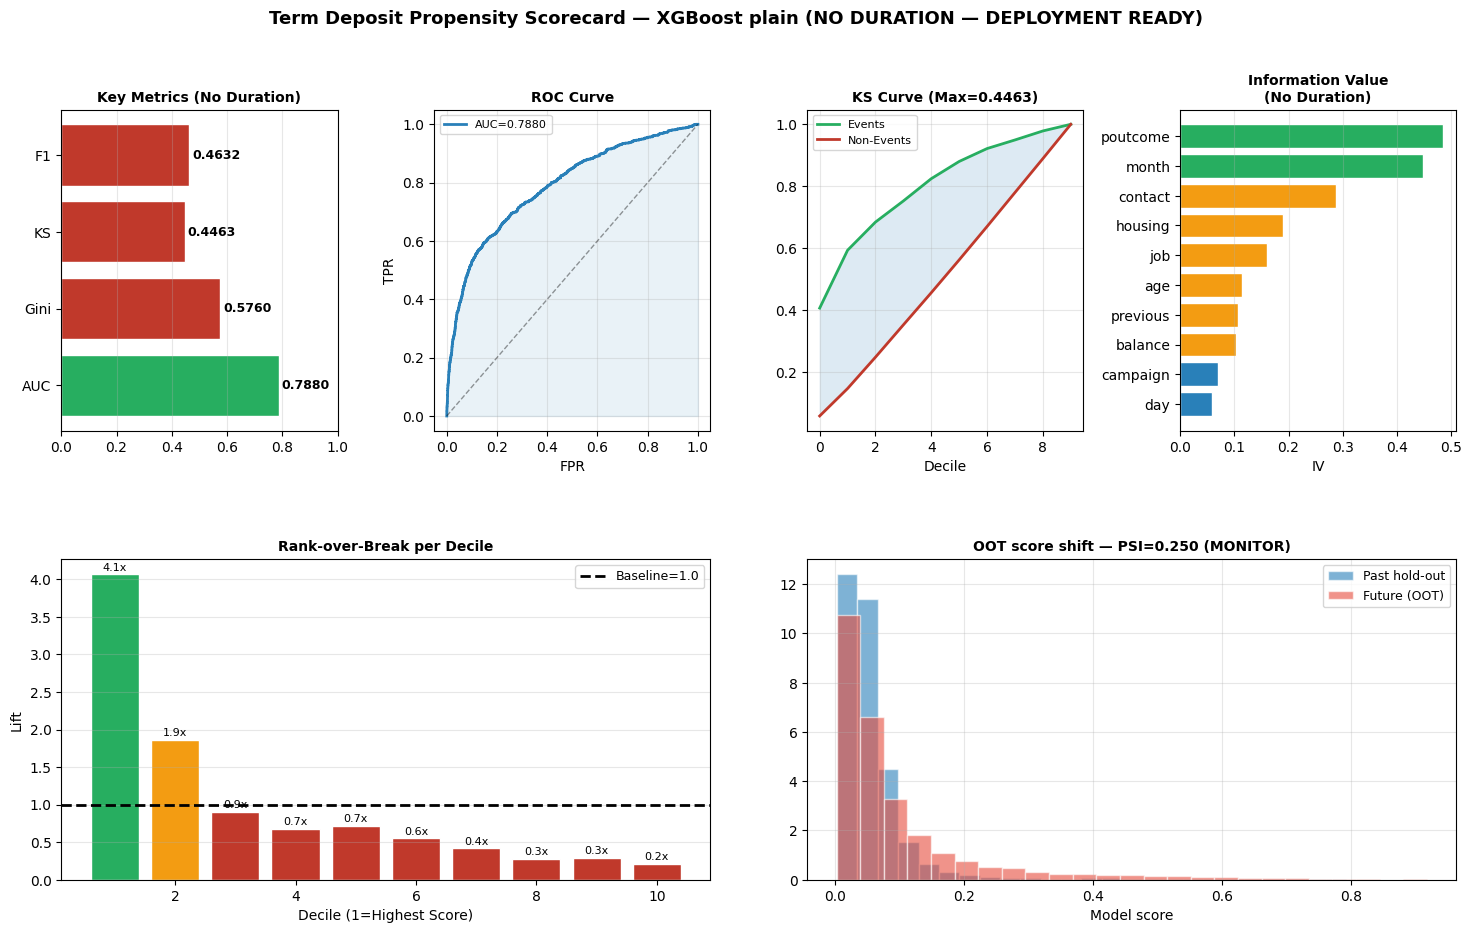

Scorecard Dashboard saved.


In [39]:
# 🔧 CHANGE #3: dashboard panel 6 now shows the out-of-time shift
# Final Scorecard Dashboard
fig = plt.figure(figsize=(18, 10))
fig.suptitle(f"Term Deposit Propensity Scorecard — {best_name} (NO DURATION — DEPLOYMENT READY)",
             fontsize=13, fontweight='bold')
gs  = fig.add_gridspec(2, 4, hspace=0.4, wspace=0.35)

# Panel 1: Key Metrics
ax1 = fig.add_subplot(gs[0, 0])
metrics_vals = [auc_final, gini_final, ks_final, f1_final]
metrics_lbls = ['AUC', 'Gini', 'KS', 'F1']
colors_gauge = ['#27AE60' if v>0.75 else '#F39C12' if v>0.60 else '#C0392B'
                for v in metrics_vals]
bars = ax1.barh(metrics_lbls, metrics_vals, color=colors_gauge, edgecolor='white')
ax1.set_xlim(0, 1)
ax1.set_title("Key Metrics (No Duration)", fontweight='bold', fontsize=10)
for b, v in zip(bars, metrics_vals):
    ax1.text(v+0.01, b.get_y()+b.get_height()/2,
             f'{v:.4f}', va='center', fontsize=9, fontweight='bold')
ax1.grid(axis='x', alpha=0.3)

# Panel 2: ROC Curve
ax2 = fig.add_subplot(gs[0, 1])
ax2.plot(fpr_f, tpr_f, color='#2980B9', lw=2, label=f'AUC={auc_final:.4f}')
ax2.plot([0,1],[0,1],'k--',lw=1,alpha=0.4)
ax2.fill_between(fpr_f, tpr_f, alpha=0.1, color='#2980B9')
ax2.set_title("ROC Curve", fontweight='bold', fontsize=10)
ax2.set_xlabel("FPR"); ax2.set_ylabel("TPR")
ax2.legend(fontsize=8); ax2.grid(alpha=0.3)

# Panel 3: KS Curve
ax3 = fig.add_subplot(gs[0, 2])
ax3.plot(dec_table['Cum_Event_Pct'],    color='#27AE60', lw=2, label='Events')
ax3.plot(dec_table['Cum_NonEvent_Pct'], color='#C0392B', lw=2, label='Non-Events')
ax3.fill_between(range(10), dec_table['Cum_Event_Pct'],
                 dec_table['Cum_NonEvent_Pct'], alpha=0.15)
ax3.set_title(f"KS Curve (Max={ks_final:.4f})", fontweight='bold', fontsize=10)
ax3.set_xlabel("Decile"); ax3.legend(fontsize=8); ax3.grid(alpha=0.3)

# Panel 4: IV Top 10
ax4 = fig.add_subplot(gs[0, 3])
top10_iv  = iv_df.head(10)
iv_colors = ['#27AE60' if v>=0.30 else '#F39C12' if v>=0.10 else '#2980B9'
             for v in top10_iv['IV']]
ax4.barh(top10_iv['feature'][::-1], top10_iv['IV'][::-1],
         color=iv_colors[::-1], edgecolor='white')
ax4.set_title("Information Value\n(No Duration)", fontweight='bold', fontsize=10)
ax4.set_xlabel("IV"); ax4.grid(axis='x', alpha=0.3)

# Panel 5: Decile Lift
ax5 = fig.add_subplot(gs[1, 0:2])
bar_c = ['#27AE60' if r>=2 else '#F39C12' if r>=1 else '#C0392B'
         for r in dec_table['Rank_over_Break']]
ax5.bar(dec_table['Decile'], dec_table['Rank_over_Break'],
        color=bar_c, edgecolor='white')
ax5.axhline(1, color='black', ls='--', lw=2, label='Baseline=1.0')
ax5.set_title("Rank-over-Break per Decile", fontweight='bold', fontsize=10)
ax5.set_xlabel("Decile (1=Highest Score)"); ax5.set_ylabel("Lift")
ax5.legend(fontsize=9); ax5.grid(axis='y', alpha=0.3)
for _, row in dec_table.iterrows():
    ax5.text(row['Decile'], row['Rank_over_Break']+0.05,
             f"{row['Rank_over_Break']:.1f}x", ha='center', fontsize=8)

# Panel 6 (CHANGE #3): out-of-time score shift
ax6 = fig.add_subplot(gs[1, 2:4])
ax6.hist(hold_scores, bins=25, alpha=0.6, density=True, color='#2980B9', label='Past hold-out', edgecolor='white')
ax6.hist(oot_scores,  bins=25, alpha=0.6, density=True, color='#E74C3C', label='Future (OOT)', edgecolor='white')
ax6.set_title(f"OOT score shift — PSI={psi_oot:.3f} ({psi_label(psi_oot).split(' —')[0]})", fontweight='bold', fontsize=10)
ax6.set_xlabel("Model score"); ax6.legend(fontsize=9); ax6.grid(alpha=0.3)

plt.savefig("19_scorecard_dashboard_nodur.png", dpi=150, bbox_inches='tight')
plt.show()
print("Scorecard Dashboard saved.")

## Section 12: Export the joblib bundle for the Streamlit app

> 🔧 **CHANGE #10 + #11.** The app needs these files: `propensity_model.joblib`, `test_scores.csv`, `features.py`, `requirements.txt`
> (plus `xgb_model.json` as a safety-net backup).
>
> **What is inside `propensity_model.joblib`?** One Python dictionary: the trained XGBoost model **and** everything needed to use it
> (feature list, balance cut-points, the two Platt-calibration numbers, thresholds, metrics, library versions).
> It holds only plain numbers/strings plus the model, so it does not depend on custom classes or lambdas.
>
> **Three safety checks run before the zip is made:** (1) train/serve parity, (2) calibration formula check,
> (3) round-trip: the saved file is re-opened and must give identical probabilities.
>
> **Joblib/pickle caveat:** a joblib file must be opened with the same `xgboost` / `scikit-learn` versions that created it.
> The cell writes a pinned `requirements.txt` for exactly that reason, and also keeps `xgb_model.json` as a version-proof fallback.

In [ ]:
# 🔧 CHANGE #11: export a single joblib bundle + JSON backup, and PROVE the saved file scores correctly
import datetime, zipfile, sys, platform
import joblib, sklearn

# --- 1) parity check: raw rows -> build_model_matrix (what the app does) must equal the training matrix
raw_cols = features.RAW_COLS
chk_idx  = list(te_idx[:300])
X_app    = build_model_matrix(df_nodur.loc[chk_idx, raw_cols], BAL_CUTS, FEATURES)
X_ref    = X_test.loc[chk_idx, FEATURES].astype(float)
assert np.allclose(X_app.values, X_ref.values), "TRAIN/SERVE SKEW: app features differ from training features!"
p_app = final_model.predict_proba(X_app)[:, 1]
assert np.allclose(p_app, final_model.predict_proba(X_ref)[:, 1])
print("✅ Parity check passed: app-side feature building reproduces the training matrix exactly.")

# --- 2) the app re-implements Platt calibration with plain numpy (a sklearn LogisticRegression / lambda would
#        add pickle risk). Prove the two-number version gives the same probabilities.
def platt_manual(p, a, b):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return 1.0 / (1.0 + np.exp(-(a * np.log(p / (1 - p)) + b)))

assert np.allclose(platt_manual(p_app, PLATT_A, PLATT_B), calibrate(p_app), atol=1e-6)
print("✅ Calibration check passed: sigmoid(a*logit(p)+b) == fitted Platt model.")

# --- 3) metadata (plain numbers/strings only -> safe to pickle, needs no custom classes to load)
meta = {
    'model_name': final_name, 'strategy': FINAL_STRATEGY, 'trained_on': str(datetime.date.today()),
    'xgboost_version': xgb.__version__, 'sklearn_version': sklearn.__version__,
    'python_version': platform.python_version(),
    'features': FEATURES, 'bal_cuts': BAL_CUTS,
    'platt_a': PLATT_A, 'platt_b': PLATT_B,
    'threshold_f1': float(opt_thr_f1), 'threshold_cost': float(opt_thr_cost),
    'cost_fn': COST_FN, 'cost_fp': COST_FP,
    'metrics': {
        'auc': float(auc_final), 'gini': float(gini_final), 'ks': float(ks_final),
        'pr_auc': float(average_precision_score(y_test, test_proba)),
        'brier': float(brier_score_loss(y_test, test_proba)),
        'f1_at_f1_thr': float(f1_final), 'precision_at_f1_thr': float(prec_final), 'recall_at_f1_thr': float(rec_final),
        'top3_decile_capture_pct': float(top3_pct), 'top_decile_lift': float(dec_table.iloc[0]['Rank_over_Break']),
        'auc_oot': float(auc_oot), 'psi_oot': float(psi_oot), 'psi_random': float(psi_val),
        'event_rate_test': float(y_test.mean()), 'n_test': int(len(y_test)), 'n_train': int(len(y_train)),
        'n_features': len(FEATURES),
    },
}

# --- 4) THE JOBLIB FILE: model + everything the app needs, in one sealed bundle
bundle = {'model': final_model, **meta}
joblib.dump(bundle, 'propensity_model.joblib', compress=3)

# backups: XGBoost native JSON (version-proof fallback), metadata for humans, scores for the dashboard charts
final_model.save_model('xgb_model.json')
json.dump(meta, open('model_meta.json', 'w'), indent=2)
pd.DataFrame({'y_true': y_test.values, 'proba': test_proba}).to_csv('test_scores.csv', index=False)

# --- 5) round-trip test: re-open the file we just wrote, as the app will, and score raw rows
loaded  = joblib.load('propensity_model.joblib')
X_back  = build_model_matrix(df_nodur.loc[chk_idx, raw_cols], loaded['bal_cuts'], loaded['features'])
p_back  = platt_manual(loaded['model'].predict_proba(X_back)[:, 1], loaded['platt_a'], loaded['platt_b'])
assert np.allclose(p_back, calibrate(final_model.predict_proba(X_ref)[:, 1]), atol=1e-6)
print("✅ Round-trip check passed: propensity_model.joblib re-loads and gives identical calibrated probabilities.")

# --- 6) requirements.txt pinned to the versions that CREATED the file (these two matter for loading it)
with open('requirements.txt', 'w') as f:
    f.write("streamlit>=1.52\npandas\nnumpy\njoblib\n"
            f"scikit-learn=={sklearn.__version__}\nxgboost=={xgb.__version__}\n")

files_to_ship = ['propensity_model.joblib', 'xgb_model.json', 'model_meta.json',
                 'test_scores.csv', 'features.py', 'requirements.txt']
with zipfile.ZipFile('app_artifacts.zip', 'w') as z:
    for f in files_to_ship:
        z.write(f)

print("\nSaved ->", ", ".join(files_to_ship), " (all inside app_artifacts.zip)")
print(f"Created with: Python {platform.python_version()} | xgboost {xgb.__version__} | scikit-learn {sklearn.__version__}")
print(f"Default threshold for the app (cost-optimal): {opt_thr_cost:.2f}")
print("Next: add app.py to the same folder, push the folder to GitHub, then deploy on Streamlit Community Cloud.")

try:
    from google.colab import files
    files.download('app_artifacts.zip')
except Exception:
    print("(Not in Colab — find app_artifacts.zip in the working folder.)")